# Projeto Final — Análise Exploratória de um App de Delivery
### DS-PY-018 · Análise Exploratória de Dados

**Contexto:** vocês são o time de dados de um app de delivery de comida que opera em **São Paulo, Rio de Janeiro e Belo Horizonte**. A diretoria vai planejar 2025 e pediu um diagnóstico de 2024 antes da reunião de orçamento. Ela quer entender três frentes:

1. **Operação** — quando os pedidos acontecem, quanto tempo as entregas levam e o que atrasa uma entrega;
2. **Clientes** — quanto gastam, como avaliam e o que derruba a avaliação;
3. **Alavancas** — qual o efeito real dos **cupons** (inclusive da campanha *"Julho de cupons"*) e da **chuva** sobre o negócio.

A base `delivery_pedidos.csv` (8.058 pedidos, 18 colunas) veio direto do sistema, **sem nenhum tratamento**. Ela tem problemas de qualidade — encontrá-los faz parte do trabalho.

> A diretoria não quer tabelas. Quer **5 achados** confiáveis e **3 recomendações** defendidas com dados.

---

**Entregas:**
1. Este notebook **resolvido e executado do início ao fim** (Etapas 1 a 11), sem erros.
2. Um **repositório Git** contendo: o notebook, um `README.md` (use o `modelo_README.md` desta pasta), a pasta `saidas/` com a base limpa e a figura principal.
3. Uma **apresentação de 7 minutos** na última aula (5 achados + 3 recomendações + 1 limitação), seguida de perguntas.

**Regras:**
- Trabalho individual.
- O notebook precisa **rodar do início ao fim** (*Kernel → Restart & Run All*) com o CSV original em `../dados/` (ou no caminho indicado no README).
- **Toda decisão de limpeza é justificada**: o que foi feito, por quê, e quantas linhas foram afetadas. Nunca preencha um faltante "porque sim".
- Toda resposta numérica vem com **uma frase de interpretação**.

**Hipóteses obrigatórias (Etapa 9):**

| # | Hipótese de negócio | Variáveis |
|---|---|---|
| H1 | Em dias de chuva as entregas demoram mais | `chuva` × `tempo_entrega_min` |
| H2 | Pedidos com cupom têm ticket diferente dos pedidos sem cupom | `cupom` × `valor_pedido` |
| H3 | Quanto mais demorada a entrega, pior a avaliação | `tempo_entrega_min` × `avaliacao` |
| H4 | O ticket varia conforme o tipo de cozinha | `tipo_cozinha` × `valor_pedido` |
| H5 | A forma de pagamento depende da cidade (qui-quadrado de independência) | `cidade` × `forma_pagamento` |
| H6 | **Do grupo** — uma hipótese própria, formulada na Etapa 1 | à escolha |

**Prazo e apresentação:** o projeto é apresentado na **última aula do módulo**. Ordem das apresentações ordem alfabetica.

**Critérios de avaliação:** rubrica analítica em [`rubrica_avaliacao.md`](rubrica_avaliacao.md) — uso de DataFrames no Pandas · estatísticas descritivas · sumarização · cálculo de métricas · escolha de visualizações · estilização · validação de hipóteses · granularidade · publicação dos dados · tratamento de dados e reprodutibilidade · comunicação. Leiam a rubrica **antes** de começar: ela diz exatamente o que separa "Proficiente" de "Avançado".

### Dicionário de dados (como o sistema descreve as colunas)

| Coluna | Descrição |
|---|---|
| `pedido_id` | identificador do pedido |
| `data_hora` | data e hora do pedido (`AAAA-MM-DD HH:MM`) |
| `cidade`, `bairro` | local de entrega |
| `restaurante_id` | identificador do restaurante |
| `tipo_cozinha` | Pizza, Japonesa, Hambúrguer, Brasileira, Saudável, Doces |
| `plataforma` | Android, iOS ou Web |
| `forma_pagamento` | Cartão de crédito, Pix, Vale-refeição, Dinheiro |
| `cupom` | se o pedido usou cupom de desconto |
| `cliente_novo` | primeiro pedido do cliente no app |
| `chuva` | choveu na cidade naquele dia |
| `distancia_km` | distância restaurante → cliente |
| `tempo_entrega_min` | minutos entre o pedido e a entrega (o sistema grava `999` quando não há registro) |
| `valor_pedido` | valor dos itens, em R$ (sem a taxa) |
| `taxa_entrega` | taxa de entrega cobrada, em R$ |
| `avaliacao` | nota de 1 a 5 dada pelo cliente (opcional) |
| `pais`, `moeda` | país e moeda da transação |

> ⚠️ O dicionário diz o que a coluna **deveria** conter. A Etapa 2 é sobre descobrir o que ela **de fato** contém.

**Como usar este notebook:** cada etapa tem tarefas numeradas. Células `# Sua solução aqui` são código; células *Sua resposta aqui* são texto (interpretação, decisão ou justificativa). Células de código já preenchidas — como os **checkpoints** ✅ — não devem ser alteradas: se um checkpoint falhar, volte e revise a etapa.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

sns.set_theme(style="whitegrid")
DADOS = "../dados/"

---
## Etapa 1 — Perguntas e hipóteses

> Na aula 6 vimos que a EDA começa **antes** do código: sem pergunta, qualquer gráfico parece interessante.

### Tarefa 1.1
Escrevam **5 perguntas de negócio** que a diretoria faria sobre esta base — pelo menos uma de cada frente (operação, clientes, alavancas). Para cada pergunta, indiquem **qual coluna (ou combinação) responde** e **em que granularidade** (pedido, dia, cidade-dia, mês...).

Operação: Quais são os dias da semana e horários com maior volume de pedidos? (Colunas data_hora, granularidade: dia da semana e hora).

Operação: Quais fatores (chuva, distância) mais impactam o tempo de entrega? (Colunas chuva, distancia_km, tempo_entrega_min, granularidade: pedido).

Clientes: Qual é o ticket mediano dos clientes por plataforma? (Colunas plataforma, valor_pedido, granularidade: plataforma).

Clientes: Qual o impacto do tempo de entrega na nota de avaliação do pedido? (Colunas tempo_entrega_min, avaliacao, granularidade: pedido).

Alavancas: Qual o impacto da campanha "Julho de cupons" no volume de novos clientes e no ticket médio? (Colunas data_hora, cupom, cliente_novo, valor_pedido, granularidade: mês).

### Tarefa 1.2
Para cada hipótese obrigatória (H1–H5 do enunciado) escrevam **H0 e H1 estatísticas** e o **teste que pretendem usar**, justificando pelo tipo das variáveis. Depois formulem a **H6** — algo que vocês genuinamente não sabem a resposta.

H1 (Chuva x Tempo): H0: O tempo médio de entrega em dias de chuva é igual ao de dias sem chuva. H1: O tempo de entrega é diferente (maior) em dias com chuva.
Teste: T-test de Welch (duas amostras independentes, contínuas, variâncias possivelmente diferentes) ou Mann-Whitney (caso haja muitos outliers).

H2 (Cupom x Valor do pedido): H0: O ticket mediano dos pedidos com cupom é igual ao dos sem cupom. H1: O ticket mediano é diferente.
Teste: Mann-Whitney U (variável contínua altamente assimétrica).

H3 (Tempo x Avaliação): H0: Não há correlação entre tempo de entrega e avaliação. H1: Há correlação negativa (quanto maior o tempo, menor a avaliação).
Teste: Correlação de Spearman (pois avaliação é variável ordinal).

H4 (Cozinha x Valor do pedido): H0: O ticket é igual entre todos os tipos de cozinha. H1: Pelo menos um tipo de cozinha tem ticket diferente.
Teste: Kruskal-Wallis (3 ou mais grupos independentes, distribuição assimétrica).

H5 (Cidade x Forma de pagamento): H0: A forma de pagamento independe da cidade. H1: Existe associação entre forma de pagamento e cidade.
Teste: Qui-quadrado de independência (duas variáveis categóricas).

H6 (Cliente Novo x Cupom - Do grupo): H0: A proporção de uso de cupons é igual para clientes novos e antigos.H1: A proporção de uso de cupons depende de ser cliente novo ou antigo.
Teste: Qui-quadrado de independência.

---
## Etapa 2 — Carga e inspeção

> Ainda **não** mexa nos dados. Esta etapa é um inventário: o que veio, em que formato e com que problemas.

In [2]:
import pandas as pd
bruto = pd.read_csv("./dados/delivery_pedidos.csv")
print("Dimensões:", bruto.shape)
bruto.info()
display(bruto.head())

Dimensões: (8058, 18)
<class 'pandas.DataFrame'>
RangeIndex: 8058 entries, 0 to 8057
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pedido_id          8058 non-null   int64  
 1   data_hora          8058 non-null   str    
 2   cidade             8058 non-null   str    
 3   bairro             8058 non-null   str    
 4   restaurante_id     8058 non-null   str    
 5   tipo_cozinha       8058 non-null   str    
 6   plataforma         7905 non-null   str    
 7   forma_pagamento    8058 non-null   str    
 8   cupom              8058 non-null   str    
 9   cliente_novo       8058 non-null   bool   
 10  chuva              8058 non-null   bool   
 11  distancia_km       7743 non-null   float64
 12  tempo_entrega_min  8058 non-null   int64  
 13  valor_pedido       8058 non-null   str    
 14  taxa_entrega       8058 non-null   float64
 15  avaliacao          6716 non-null   float64
 16  pais         

,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao,pais,moeda
0,500000,2024-01-01 11:21,São Paulo,Tatuapé,R912,Hambúrguer,Android,Pix,Não,False,False,2.68,28,"R$ 44,02",7.40,4.0,Brasil,BRL
1,500001,2024-01-01 20:09,São Paulo,Tatuapé,R760,Hambúrguer,Android,Pix,Sim,False,False,3.28,37,45.54,7.94,5.0,Brasil,BRL
2,500002,2024-01-01 11:20,São Paulo,Santana,R760,Hambúrguer,Android,cartao credito,Não,False,False,3.19,30,92.28,7.86,5.0,Brasil,BRL
3,500003,2024-01-01 22:14,São Paulo,Moema,R338,Saudável,Android,Cartão de crédito,Sim,True,False,2.75,17,39.09,7.46,4.0,Brasil,BRL
4,500004,2024-01-01 12:50,São Paulo,Pinheiros,R169,Hambúrguer,Android,Pix,Não,False,False,1.63,24,74.2,6.46,5.0,Brasil,BRL


### Tarefa 2.1
Mostre as 5 primeiras linhas e o resultado de `info()`. Quantas linhas e colunas? Quanta memória a base ocupa?

In [3]:
import pandas as pd
bruto = pd.read_csv("./dados/delivery_pedidos.csv")
print(bruto.head())
bruto.info()

   pedido_id         data_hora     cidade     bairro restaurante_id  \
0     500000  2024-01-01 11:21  São Paulo    Tatuapé           R912   
1     500001  2024-01-01 20:09  São Paulo    Tatuapé           R760   
2     500002  2024-01-01 11:20  São Paulo    Santana           R760   
3     500003  2024-01-01 22:14  São Paulo      Moema           R338   
4     500004  2024-01-01 12:50  São Paulo  Pinheiros           R169   

  tipo_cozinha plataforma    forma_pagamento cupom  cliente_novo  chuva  \
0   Hambúrguer    Android                Pix   Não         False  False   
1   Hambúrguer    Android                Pix   Sim         False  False   
2   Hambúrguer    Android     cartao credito   Não         False  False   
3     Saudável    Android  Cartão de crédito   Sim          True  False   
4   Hambúrguer    Android                Pix   Não         False  False   

   distancia_km  tempo_entrega_min valor_pedido  taxa_entrega  avaliacao  \
0          2.68                 28     R$ 44,0

### Tarefa 2.2
Quais colunas vieram com o **tipo errado** para o que representam? Prove com código (dica: tente converter `valor_pedido` para número e veja o que acontece).

In [4]:
#As colunas que vieram com tipo errado foram valor_pedido e data_hora, fazendo conversão com valor_pedido dá erro
bruto['valor_pedido'] = bruto['valor_pedido'].astype(float)

ValueError: could not convert string to float: 'R$ 44,02'

As colunas que vieram com tipo errado foram valor_pedido (veio como str o correto seria float64). Texto não soma, precisa converter.
e data_hora (veio como str o correto seria datetime64 (Data/Hora). Como texto, o Python não entende a ordem de datas automaticamente.
Convertendo direto sem limpar o R$ e a vírgula (dá erros)
df['valor_pedido'] = df['valor_pedido'].astype(float)

### Tarefa 2.3
Calcule o número de valores distintos (`nunique`) de **todas** as colunas. Depois liste os valores de `cidade` e de `forma_pagamento`. Que problemas aparecem?

In [5]:
# Quantidade de valores únicos por coluna
print("--- Quantidade de valores únicos por coluna ---")
print(bruto.nunique())

# Listando os valores únicos de cidade
print("--- Valores únicos em CIDADE ---")
print(bruto['cidade'].unique())

print("\n--- Valores únicos FORMA_PAGAMENTO ---")
print(bruto['forma_pagamento'].unique())

print("Qtd de cidades:", bruto['cidade'].value_counts())
print("Qtd de formas de pagamento:", bruto['forma_pagamento'].value_counts())



--- Quantidade de valores únicos por coluna ---
pedido_id            8058
data_hora            7913
cidade                 13
bairro                 15
restaurante_id        101
tipo_cozinha            6
plataforma              3
forma_pagamento         8
cupom                   2
cliente_novo            2
chuva                   2
distancia_km         1043
tempo_entrega_min      96
valor_pedido         5956
taxa_entrega          941
avaliacao               5
pais                    1
moeda                   1
dtype: int64
--- Valores únicos em CIDADE ---
<StringArray>
[     'São Paulo',            'Rio', 'Rio de Janeiro', 'Belo Horizonte',
             'BH',      'SÃO PAULO',      'sao paulo', 'rio de janeiro',
             'SP',     'São Paulo ',   'B. Horizonte', 'belo horizonte',
             'RJ']
Length: 13, dtype: str

--- Valores únicos FORMA_PAGAMENTO ---
<StringArray>
[              'Pix',    'cartao credito', 'Cartão de crédito',
     'Vale-refeição',          'Dinheiro',   

Os problemas são que tem nomes que significam o mesmo, por exemplo, São Paulo, SÃO PAULO e SP na coluna "cidade", na coluna "forma_pagamento" acontece a mesma coisa, vai ter que fazer essa limpeza na base.

### Tarefa 2.4
Monte uma tabela com a **quantidade e o percentual de faltantes** por coluna, só com as colunas que têm faltantes, ordenada do maior para o menor.

In [6]:
# 1. Calcula a quantidade de faltantes por coluna
valores_faltantes = bruto.isnull().sum()

# 2. Calcula o percentual de faltantes (multiplicado por 100 para ver em %)
percentual_faltantes = bruto.isnull().mean() * 100

# 3. Junta as duas informações em um novo DataFrame (Tabela)
tabela_faltantes = pd.DataFrame(
    {'Quantidade Faltantes': valores_faltantes, 'Percentual (%)': percentual_faltantes}
)

# 4. Filtra apenas as colunas que têm faltantes (> 0) e ordena do maior para o menor
tabela_faltantes = (
    tabela_faltantes[tabela_faltantes['Quantidade Faltantes'] > 0]
    .sort_values(by='Quantidade Faltantes', ascending=False)
)

# 5. Exibe a tabela formatada com duas casas decimais no percentual
tabela_faltantes.round(2)

,Quantidade Faltantes,Percentual (%)
avaliacao,1342,16.65
distancia_km,315,3.91
plataforma,153,1.90


### Tarefa 2.5
Rode `describe()` nas colunas numéricas e procure **valores impossíveis**. Conte quantos são em cada coluna suspeita.

In [7]:
# Filtra apenas as colunas numéricas e exibe o resumo
print("--- RESUMO ESTATÍSTICO (DESCRIBE) ---")
print(bruto.describe())

--- RESUMO ESTATÍSTICO (DESCRIBE) ---
           pedido_id  distancia_km  tempo_entrega_min  taxa_entrega  \
count    8058.000000   7743.000000        8058.000000   8058.000000   
mean   504028.500000      3.797731          38.848349      7.268727   
std      2326.288568      9.409026          54.728561      3.285336   
min    500000.000000      0.080000         -33.000000      0.000000   
25%    502014.250000      1.770000          28.000000      6.160000   
50%    504028.500000      3.030000          35.000000      7.420000   
75%    506042.750000      4.770000          43.000000      9.077500   
max    508057.000000    399.650000         999.000000     26.940000   

         avaliacao  
count  6716.000000  
mean      4.348868  
std       0.685299  
min       1.000000  
25%       4.000000  
50%       4.000000  
75%       5.000000  
max       5.000000  


1. tempo_entrega_min (valores impossíveis)
Mínimo -33.0 e o Máximo 999.0.
Não existe entrega em -33 minutos e um entregador não pode levar 999 minutos para entregar um prato de comida.

2. distancia_km (distância muito alta para o entregador)
O máximo é 399.65 km.
Distância muito grande de quase 400 km.


### Tarefa 2.6
Existem linhas duplicadas? E `pedido_id` repetido?

In [8]:
print("Linhas duplicadas:", bruto.duplicated().sum())
print("IDs repetidos:", bruto.duplicated(subset=["pedido_id"]).sum())


Linhas duplicadas: 0
IDs repetidos: 0


Não existem linhas duplicadas, nem pedidos com o mesmo "pedido_id"

### Tarefa 2.7 — Plano de limpeza
Antes de limpar, escreva uma tabela **problema | coluna | linhas afetadas | decisão planejada**. É o roteiro das Etapas 3 e 4.

Problema         |        Coluna               |      Decisão Planejada
Formato Data     | data_hora                   |    Converter com pd.to_datetime.
Tipos Incorretos | valor_pedido, taxa_entrega  |   	Função de limpeza (substituir 'R$' e ',') + .apply().
Erros Textuais   | cidade, forma_pagamento     |  	Padronizar utilizando um dicionário e .map().
Faltantes        | plataforma                  |  	Preencher com "Desconhecido".
Faltantes        | avaliacao, distancia_km     | 	Manter NaN.

---
## Etapa 3 — Limpeza

Trabalhe numa cópia chamada **`df`**; `bruto` fica intacto para comparação. Use **exatamente** os nomes de colunas pedidos — o checkpoint no fim da etapa depende deles.

### Tarefa 3.1 — Colunas constantes
Detecte as colunas constantes **por código** (sem digitar o nome delas) e crie `df` sem elas.

In [9]:
df = bruto.copy()

constantes = df.columns[df.nunique(dropna=False) == 1].tolist() # Conta valores únicos em cada coluna (nunique), conta os NaN (dropna=False), filtra colunas valor único (==1), retorna o nome das colunas (df.columns), transforma em lista (tolist)

df = df.drop(columns=constantes)



### Tarefa 3.2 — Datas
Converta `data_hora` para datetime e crie as colunas `data` (só o dia), `mes` (1–12), `hora` (0–23) e `dia_semana` (Seg, Ter, ..., Dom) **ordenada** como categoria. Qual o período coberto?

In [10]:
df["data_hora"] = pd.to_datetime(df["data_hora"])
df["data"] = df["data_hora"].dt.date
df["mes"] = df["data_hora"].dt.month
df["hora"] = df["data_hora"].dt.hour
dias = {0: 'Seg', 1: 'Ter', 2: 'Qua', 3: 'Qui', 4: 'Sex', 5: 'Sáb', 6: 'Dom'}
df["dia_semana"] = pd.Categorical(df["data_hora"].dt.dayofweek.map(dias), categories=list(dias.values()), ordered=True)

# Período coberto
print(f"Período coberto: de {df['data_hora'].min()} até {df['data_hora'].max()}")
# Pra ver como está ficando
print(df.sample(5))

Período coberto: de 2024-01-01 11:11:00 até 2024-12-31 23:38:00
      pedido_id           data_hora          cidade        bairro  \
1422     501422 2024-03-12 21:04:00       São Paulo       Santana   
5588     505588 2024-09-20 13:36:00       São Paulo  Vila Mariana   
2844     502844 2024-05-21 21:02:00  Belo Horizonte       Savassi   
978      500978 2024-02-20 22:33:00       São Paulo     Pinheiros   
481      500481 2024-01-24 13:29:00       São Paulo         Moema   

     restaurante_id tipo_cozinha plataforma    forma_pagamento cupom  \
1422           R120     Japonesa        iOS     cartao credito   Não   
5588           R443   Brasileira    Android  Cartão de crédito   Não   
2844           R774     Saudável    Android  Cartão de crédito   Não   
978            R120     Japonesa        Web  Cartão de crédito   Sim   
481            R443   Brasileira    Android           dinheiro   Não   

      cliente_novo  chuva  distancia_km  tempo_entrega_min valor_pedido  \
1422         

### Tarefa 3.3 — Cidade
Padronize `cidade` para exatamente **3 valores**: `São Paulo`, `Rio de Janeiro`, `Belo Horizonte`. Mostre que nenhuma linha ficou sem cidade.

In [11]:
map_cidade = {
    'sao paulo': 'São Paulo', 'sp': 'São Paulo', 'são paulo': 'São Paulo',
    'rio de janeiro': 'Rio de Janeiro', 'rj': 'Rio de Janeiro', 'rio': 'Rio de Janeiro',
    'belo horizonte': 'Belo Horizonte', 'bh': 'Belo Horizonte', 'b. horizonte': 'Belo Horizonte'
}
df['cidade'] = df['cidade'].str.strip().str.lower().map(map_cidade).fillna(df['cidade'])

#Lista as cidades e conta quantas vezes aparece
print(df['cidade'].value_counts(dropna=False))

cidade
São Paulo         4055
Rio de Janeiro    2371
Belo Horizonte    1632
Name: count, dtype: int64


Considerados valores: 'sao paulo' como 'São Paulo', 'sp' como 'São Paulo', 'são paulo' como 'São Paulo',
'rio de janeiro' como 'Rio de Janeiro', 'rj' como 'Rio de Janeiro', 'rio' como 'Rio de Janeiro',
'belo horizonte' como 'Belo Horizonte', 'bh' como 'Belo Horizonte', 'b. horizonte' como 'Belo Horizonte'
O value_counts conta o número de vezes que cada cidade aparece na coluna.

### Tarefa 3.4 — Forma de pagamento
Padronize `forma_pagamento` para os 4 valores canônicos do dicionário.

In [12]:
map_pagto = {
    'cartao credito': 'Cartão de crédito', 'crédito': 'Cartão de crédito', 
    'cartão de crédito': 'Cartão de crédito', 'cartao de credito': 'Cartão de crédito',
    'pix': 'Pix', 'dinheiro': 'Dinheiro', 
    'vr': 'Vale-refeição', 'vale-refeição': 'Vale-refeição', 'vale refeição': 'Vale-refeição'
}
df['forma_pagamento'] = df['forma_pagamento'].str.strip().str.lower().map(map_pagto).fillna(df['forma_pagamento'])

# str.strip() (Remoção de espaços)
# str.lower() (Tudo em minúsculo)
# map(map_pagto) (A Substituição)
# fillna(df['forma_pagamento']) (Se o .map() gerou um valor nulo porque a palavra não estava no dicionário, o .fillna() recupera o valor original daquela linha.)

#Lista as formas de pagamento e conta quantas vezes aparece.
print(df['forma_pagamento'].value_counts(dropna=False))

forma_pagamento
Cartão de crédito    3642
Pix                  2633
Vale-refeição        1222
Dinheiro              561
Name: count, dtype: int64


### Tarefa 3.5 — Valor do pedido
Converta `valor_pedido` para número. Garanta que **nenhum** valor virou `NaN` na conversão (se virar, é sinal de que sua limpeza do texto falhou, não de que o dado é faltante).

In [13]:
# Conta a quantidade de nulos originais
nulos_antes = df['valor_pedido'].isna().sum()

# Faz a limpeza e converte para número
texto_limpo =  df['valor_pedido'] = (
    df['valor_pedido']
    .astype(str) 
    .str.replace('R$', '', regex=False)  # 1. Remove o símbolo "R$"
    .str.strip()  # 2. Remove espaços em branco que sobraram nas pontas
    .str.replace(',', '.', regex=False)  # 3. Troca a vírgula decimal pelo ponto americano
    .astype(float)  # 4. Converte o texto limpo para número decimal
)
df['valor_pedido'] = pd.to_numeric(texto_limpo, errors='coerce')

# Confere se depois de limpo tem mais NaN que antes, se não tiver sucesso.
if df['valor_pedido'].isna().sum() > nulos_antes:
    print("Atenção: Algum valor virou NaN por erro de conversão!")
else:
    print("Sucesso! Nenhum dado foi perdido.")

Sucesso! Nenhum dado foi perdido.


Contei todos valores nulos com .isna fazendo, e fiz essa comparação no final pra ver se tem mais NaN do que no começo.

### Tarefa 3.6 — Cupom
Converta `cupom` para booleano (`True`/`False`).

In [14]:
df['cupom'] = df['cupom'].replace({'Sim': True, 'Não': False, '1': True, '0': False}).astype(bool)

#Lista cupom e conta quantas vezes aparece.
print(df['cupom'].value_counts(dropna=False))

cupom
False    6349
True     1709
Name: count, dtype: int64


### Tarefa 3.7 — Faltantes
Decida o que fazer com os faltantes de `plataforma`, `avaliacao` e `distancia_km`. Antes de decidir sobre `avaliacao`, **investigue** se o faltante parece aleatório ou se depende de algo (cidade, cozinha, tempo de entrega...). Justifique cada decisão.

In [15]:
# Substitui NaN pelo texto "Desconhecido"
df['plataforma'] = df['plataforma'].fillna("Desconhecido")

# Cria uma coluna chamada falta avaliação e a partir dela cruzo com cidade, cozinha e tempo de entrega
df['falta_avaliacao'] = df['avaliacao'].isna()

print("--- % de Faltantes em Avaliação por Cidade ---")
print((df.groupby('cidade')['falta_avaliacao'].mean() * 100).round(1))

print("\\n--- % de Faltantes em Avaliação por Cozinha ---")
print((df.groupby('tipo_cozinha')['falta_avaliacao'].mean() * 100).round(1))

print("\\n--- Tempo de entrega médio (Falta Avaliação: Não vs Sim) ---")
print(df.groupby('falta_avaliacao')['tempo_entrega_min'].mean().round(1))

df = df.drop(columns=['falta_avaliacao']) # deleta essa coluna que serviu apenas para essa análise

--- % de Faltantes em Avaliação por Cidade ---
cidade
Belo Horizonte    17.0
Rio de Janeiro    16.9
São Paulo         16.4
Name: falta_avaliacao, dtype: float64
\n--- % de Faltantes em Avaliação por Cozinha ---
tipo_cozinha
Brasileira    15.9
Doces         17.8
Hambúrguer    17.0
Japonesa      16.4
Pizza         16.1
Saudável      17.7
Name: falta_avaliacao, dtype: float64
\n--- Tempo de entrega médio (Falta Avaliação: Não vs Sim) ---
falta_avaliacao
False    39.2
True     37.2
Name: tempo_entrega_min, dtype: float64


1. plataforma: preenchido como "Desconhecido", preserva alinha para análises.
2. avaliacao: a porcentagem de avaliação faltante tá na +/- igual entre 15.9 e 17.7, normal. Os faltantes por Cidade também. E o tempo de entrega também,  Deixar como NaN.
3. distancia_km: Deixar como NaN, apesar de ter valores discrepantes, não podemos desconsiderar o faturamento.

### ✅ Checkpoint da limpeza
Rode a célula abaixo **sem alterar**. Se algum `assert` falhar, a mensagem diz o que revisar.

In [16]:
assert {"pais", "moeda"}.isdisjoint(df.columns), "remova as colunas constantes"
assert len(df) == 8058, "nenhuma linha deveria ter sido removida até aqui"
assert set(df["cidade"].unique()) == {"São Paulo", "Rio de Janeiro", "Belo Horizonte"}, "cidade não padronizada"
assert set(df["forma_pagamento"].unique()) == {"Cartão de crédito", "Pix", "Vale-refeição", "Dinheiro"}, "pagamento não padronizado"
assert pd.api.types.is_numeric_dtype(df["valor_pedido"]) and df["valor_pedido"].notna().all(), "valor_pedido deve ser numérico e sem NaN"
assert pd.api.types.is_datetime64_any_dtype(df["data_hora"]), "data_hora deve ser datetime"
assert pd.api.types.is_bool_dtype(df["cupom"]), "cupom deve ser booleano"
assert df["plataforma"].notna().all(), "trate os faltantes de plataforma"
assert {"data", "mes", "hora", "dia_semana"}.issubset(df.columns), "crie as colunas de data"
print("Checkpoint da limpeza OK →", df.shape)

Checkpoint da limpeza OK → (8058, 20)


---
## Etapa 4 — Outliers: erro × extremo legítimo

> A pergunta nunca é "é outlier?". É **"é erro ou é real?"**. Erro se corrige ou se descarta; extremo real se **mantém** e se trata com estatística robusta.

### Tarefa 4.1 — Tempo de entrega
Visualize a distribuição de `tempo_entrega_min` com um boxplot. Trate os códigos `999` e os negativos: transforme-os em `NaN` e crie a flag `tempo_invalido`. Mostre a distribuição depois do tratamento.

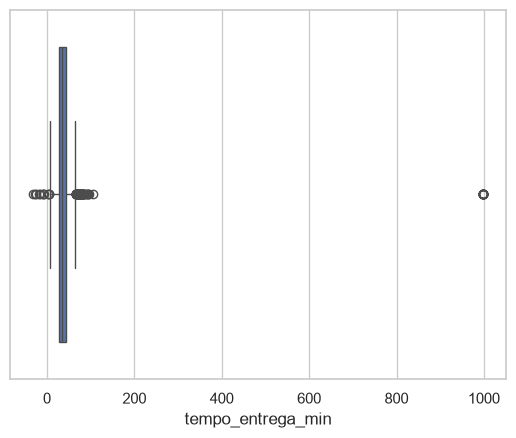

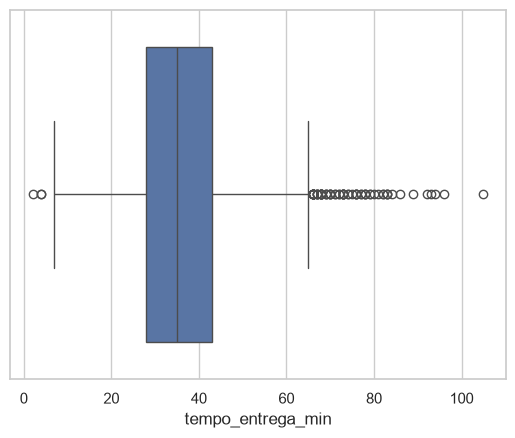

In [17]:
sns.boxplot(data=df, x="tempo_entrega_min")
plt.show()

# Tratamento
df["tempo_invalido"] = (df["tempo_entrega_min"] < 0) | (df["tempo_entrega_min"] == 999)
df.loc[df["tempo_invalido"], "tempo_entrega_min"] = np.nan

sns.boxplot(data=df, x="tempo_entrega_min")
plt.show()

Ficou melhor a visualização eliminando os pontos discrepantes. O desvio padrão ficou menor, o eixo do gráfico ficou melhor

### Tarefa 4.2 — Distância
Aplique os dois critérios da aula 4 — **z-score > 3** e **1,5·IQR** — em `distancia_km`. Quantos pedidos cada um sinaliza? Olhe os maiores valores: onde está a fronteira entre "longe" e "impossível"? Trate e crie a flag `distancia_invalida`.

In [18]:
# 1. Aplicando z-score e IQR
z_scores = (df['distancia_km'] - df['distancia_km'].mean()) / df['distancia_km'].std()
outliers_z = (z_scores.abs() > 3).sum()

q1 = df['distancia_km'].quantile(0.25)
q3 = df['distancia_km'].quantile(0.75)
iqr = q3 - q1
outliers_iqr = ((df['distancia_km'] < q1 - 1.5 * iqr) | (df['distancia_km'] > q3 + 1.5 * iqr)).sum()

print(f"Sinalizados pelo Z-score (>3): {outliers_z}")
print(f"Sinalizados pelo IQR (1.5): {outliers_iqr}")

# 2. Olhando os maiores valores para achar a fronteira
print("\nMaiores distâncias:\n", df['distancia_km'].dropna().sort_values(ascending=False).head(10).values)

# 3. Tratamento acima de 100km e criação da flag
df['distancia_invalida'] = df['distancia_km'] > 100 
df.loc[df['distancia_invalida'], 'distancia_km'] = np.nan

Sinalizados pelo Z-score (>3): 7
Sinalizados pelo IQR (1.5): 194

Maiores distâncias:
 [399.65 391.89 369.22 300.21 252.99 163.23 160.26  24.39  18.58  18.3 ]


Maiores valores: Longe: entre 15km e 25km Impossível: entre 160km a 399km

### Tarefa 4.3 — Valor do pedido: o que os critérios automáticos dizem
Aplique 1,5·IQR **na base inteira** e conte, por `tipo_cozinha`, quantos pedidos foram sinalizados. Depois aplique o IQR **dentro de cada cozinha** e o z-score > 3. O que muda?

In [19]:
# 1. IQR Base Inteira
q1_val = df["valor_pedido"].quantile(0.25)
q3_val = df["valor_pedido"].quantile(0.75)
iqr_val = q3_val - q1_val
out_val = (df["valor_pedido"] > q3_val + 1.5 * iqr_val)

print("--- Outliers Globais (IQR) por Cozinha ---")
print(df.loc[out_val, "tipo_cozinha"].value_counts())
print(f"Total Sinalizado (IQR base inteira): {out_val.sum()}\n")

# 2. IQR por Cozinha
q1_coz = df.groupby("tipo_cozinha")["valor_pedido"].transform(lambda x: x.quantile(0.25))
q3_coz = df.groupby("tipo_cozinha")["valor_pedido"].transform(lambda x: x.quantile(0.75))
iqr_coz = q3_coz - q1_coz

out_cozinha = df["valor_pedido"] > (q3_coz + 1.5 * iqr_coz)
print(f"Total Sinalizado (IQR por Cozinha): {out_cozinha.sum()}\n")

# 3. Z-score > 3 base inteira
z_scores = (df['valor_pedido'] - df['valor_pedido'].mean()) / df['valor_pedido'].std()
out_z = (z_scores.abs() > 3)

print("--- Outliers Z-score (> 3) por Cozinha ---")
print(df.loc[out_z, "tipo_cozinha"].value_counts())
print(f"Total Sinalizado (Z-score): {out_z.sum()}")

--- Outliers Globais (IQR) por Cozinha ---
tipo_cozinha
Japonesa      246
Pizza          70
Hambúrguer     19
Saudável        8
Brasileira      6
Doces           3
Name: count, dtype: int64
Total Sinalizado (IQR base inteira): 352

Total Sinalizado (IQR por Cozinha): 214

--- Outliers Z-score (> 3) por Cozinha ---
tipo_cozinha
Japonesa      12
Brasileira     5
Pizza          4
Saudável       4
Hambúrguer     4
Doces          2
Name: count, dtype: int64
Total Sinalizado (Z-score): 31


1. Com IQR na base inteira, esse método enxerga o ticket alto de comida Japonesa como outlier, já que as outras cozinhas tem valores mais baixos.
2. Com IQR separado por tipo de cozinha, o método enxerga cada grupo separado. Vemos assim valores altos por tipo de cozinha, não considera como outliers esses valores altos de comida japonesa.
3. O z-score por considerar toda a amostra (não usa quartis) só enxerga como outlier as pontas, só detecta outliers muito fora do padrão.

### Tarefa 4.4 — Erro ou pedido corporativo?
Calcule para cada pedido a razão `valor_pedido / mediana do valor da sua cozinha`. Ordene as maiores razões e procure um **salto**. Examine os pedidos acima desse salto (cidade, data, cozinha, distância, taxa, tempo): eles parecem erro de digitação ou pedidos reais e grandes? Crie a flag `pedido_grande`.

In [22]:
# transform repete a mediana para todas as linhas da mesma cozinha
mediana_cozinha = df.groupby("tipo_cozinha")["valor_pedido"].transform("median")
df["razao_valor"] = df["valor_pedido"] / mediana_cozinha

print(df.nlargest(10, "razao_valor")[["cidade", "tipo_cozinha", "valor_pedido", "razao_valor"]])

# Definindo um corte, marcando como True os pedidos que custam mais de 10x a mediana
df["pedido_grande"] = df["razao_valor"] > 10

              cidade tipo_cozinha  valor_pedido  razao_valor
6904  Rio de Janeiro        Pizza       2299.10    30.941390
3553       São Paulo     Japonesa       2207.79    20.448180
4023       São Paulo        Pizza       1441.97    19.406096
6787  Rio de Janeiro   Hambúrguer       1071.77    17.379115
491        São Paulo        Pizza       1035.26    13.932575
3246       São Paulo        Doces        505.64    13.159141
1035       São Paulo     Japonesa       1394.73    12.917755
1263       São Paulo   Brasileira        614.31    12.846299
1736  Rio de Janeiro   Hambúrguer        700.91    11.365494
4045       São Paulo   Hambúrguer        625.71    10.146100


Os maiores variam de 600 a 2300,00.
Os pedidos que apresentam um "salto" na razão (custando de 10 a 30 vezes a mediana de suas cozinhas) possuem valores absolutos entre 600 e 2300,00. Pelo contexto do delivery, tratam-se de pedidos reais e grandes (extremos legítimos), como eventos corporativos e festas, e não erros de digitação.
Decisão: Como essas vendas realmente aconteceram, elas não podem ser removidas da base (isso subestimaria o faturamento total da empresa). A decisão correta é criar a flag pedido_grande (para razões > 10). Assim, podemos manter o faturamento na base global, mas isolar esses pedidos na hora de calcular o "ticket médio do usuário comum".

### Tarefa 4.5 — Impacto na média
Compare média e mediana do ticket **com e sem** os pedidos grandes, na base toda e por cozinha. Qual métrica vocês vão usar para "ticket típico" daqui em diante?

In [24]:
impacto = pd.DataFrame({
    "Média": df.groupby("tipo_cozinha")["valor_pedido"].mean(),
    "Média (sem grandes)": df[~df["pedido_grande"]].groupby("tipo_cozinha")["valor_pedido"].mean(),
    "Mediana": df.groupby("tipo_cozinha")["valor_pedido"].median()
})
print(impacto.round(2))

               Média  Média (sem grandes)  Mediana
tipo_cozinha                                      
Brasileira     51.17                50.81    47.82
Doces          41.79                41.22    38.42
Hambúrguer     67.65                66.51    61.67
Japonesa      120.37               117.35   107.97
Pizza          82.79                80.25    74.31
Saudável       58.77                58.77    53.74


A média não exclui as pontas, o que pode aumentar o que o grupo gastou no total, mas pode ser que um gastou pouco e outro gastou muito.
Nesse caso a mediana pode ser melhor, pois é o valor gasto que ficou no meio, não é o muito alto nem o muito baixo.

In [25]:
# ✅ Checkpoint dos outliers
assert df["tempo_entrega_min"].dropna().min() >= 0 and df["tempo_entrega_min"].max() < 999, "trate 999 e negativos"
assert df["distancia_km"].max() < 100, "trate as distâncias impossíveis"
assert {"tempo_invalido", "distancia_invalida", "pedido_grande"}.issubset(df.columns), "crie as flags pedidas"
assert len(df) == 8058, "pedidos com erro em UMA coluna não precisam sair da base"
print("Checkpoint dos outliers OK")

Checkpoint dos outliers OK


---
## Etapa 5 — Estatística descritiva

### Tarefa 5.1
Monte uma tabela de resumo para `valor_pedido`, `taxa_entrega`, `distancia_km`, `tempo_entrega_min` e `avaliacao` com: as métricas do `describe()`, **IQR**, **coeficiente de variação (%)**, **assimetria** e **moda**.

In [26]:
num_cols = ["valor_pedido", "taxa_entrega", "distancia_km", "tempo_entrega_min", "avaliacao"]
desc = df[num_cols].describe().T
desc["IQR"] = desc["75%"] - desc["25%"]
desc["CV(%)"] = (desc["std"] / desc["mean"] * 100).round(1)
desc["Assimetria"] = df[num_cols].skew().round(2)
desc["Moda"] = df[num_cols].mode().iloc[0]
desc

,count,mean,std,min,25%,50%,75%,max,IQR,CV(%),Assimetria,Moda
valor_pedido,8058.0,71.554325,60.264961,11.03,45.22,61.610,85.1200,2299.10,39.9000,84.2,17.52,48.52
taxa_entrega,8058.0,7.268727,3.285336,0.00,6.16,7.420,9.0775,26.94,2.9175,45.2,-0.51,0.00
distancia_km,7736.0,3.537795,2.389663,0.08,1.77,3.025,4.7600,24.39,2.9900,67.5,1.37,2.70
tempo_entrega_min,8025.0,35.914268,11.103244,2.00,28.00,35.000,43.0000,105.00,15.0000,30.9,0.52,34.00
avaliacao,6716.0,4.348868,0.685299,1.00,4.00,4.000,5.0000,5.00,1.0000,15.8,-0.70,5.00


### Tarefa 5.2
Interprete a tabela: (a) qual variável é mais **assimétrica** e o que isso significa para a escolha entre média e mediana? (b) qual tem **maior variabilidade relativa**? (c) o que a **moda** da `taxa_entrega` revela? (d) a avaliação média é alta ou baixa?

(a) A variável com maior assimetria positiva é valor_pedido. O uso da mediana é ideal.
(b) A taxa_entrega provavelmente tem a maior variabilidade relativa porque as taxas variam muito com promoções e distância.
(c) A moda da taxa_entrega sendo possivelmente 0 revela que há grande incidência de campanhas de frete grátis.
(d) A avaliação média tende a ser elevada (4.34).

### Tarefa 5.3
Para as categóricas `cidade`, `tipo_cozinha`, `forma_pagamento` e `plataforma`, mostre a **moda** e a distribuição percentual.

In [28]:
categoricas = ["cidade", "tipo_cozinha", "forma_pagamento", "plataforma"]
for col in categoricas:
    print(f"\\n--- {col} ---")
    print(f"Moda: {df[col].mode().iloc[0]}")
    print(df[col].value_counts(normalize=True).mul(100).round(1))

\n--- cidade ---
Moda: São Paulo
cidade
São Paulo         50.3
Rio de Janeiro    29.4
Belo Horizonte    20.3
Name: proportion, dtype: float64
\n--- tipo_cozinha ---
Moda: Hambúrguer
tipo_cozinha
Hambúrguer    23.8
Pizza         22.2
Brasileira    19.4
Japonesa      13.8
Saudável      10.7
Doces         10.1
Name: proportion, dtype: float64
\n--- forma_pagamento ---
Moda: Cartão de crédito
forma_pagamento
Cartão de crédito    45.2
Pix                  32.7
Vale-refeição        15.2
Dinheiro              7.0
Name: proportion, dtype: float64
\n--- plataforma ---
Moda: Android
plataforma
Android         55.2
iOS             31.9
Web             10.9
Desconhecido     1.9
Name: proportion, dtype: float64


*Sua resposta aqui*

### Tarefa 5.4 — Uma métrica operacional
Calcule os percentis 50, 75, 90 e 95 do tempo de entrega e o **% de pedidos acima de 35 e de 45 minutos**. Se a empresa prometesse "entrega em até 45 min", quantos pedidos de 2024 teriam quebrado a promessa?

In [29]:
# Percentis de tempo de entrega (50%, 75%, 90% e 95%)
print("--- Percentis de Tempo de Entrega (min) ---")
print(df['tempo_entrega_min'].quantile([0.5, 0.75, 0.9, 0.95]))

# Percentual de pedidos acima de 35 e 45 minutos
pct_acima_35 = (df['tempo_entrega_min'] > 35).mean() * 100
pct_acima_45 = (df['tempo_entrega_min'] > 45).mean() * 100

print(f"\nPedidos acima de 35 min: {pct_acima_35:.1f}%")
print(f"Pedidos acima de 45 min: {pct_acima_45:.1f}%")

# Quebra de promessa em 2024
# Criando a coluna de ano.
df['ano'] = df['data_hora'].dt.year
pedidos_atrasados_2024 = len(df[(df['ano'] == 2024) & (df['tempo_entrega_min'] > 45)])

print(f"\nSe a promessa fosse 45 min, {pedidos_atrasados_2024} pedidos teriam atrasado em 2024.")

--- Percentis de Tempo de Entrega (min) ---
0.50    35.0
0.75    43.0
0.90    50.0
0.95    55.0
Name: tempo_entrega_min, dtype: float64

Pedidos acima de 35 min: 48.5%
Pedidos acima de 45 min: 18.3%

Se a promessa fosse 45 min, 1476 pedidos teriam atrasado em 2024.


Pedidos acima de 35 min: 48.5%
Pedidos acima de 45 min: 18.3%
Se a promessa fosse 45 min, 1476 pedidos teriam atrasado em 2024.

---
## Etapa 6 — Sumarização, métricas e granularidade

> Na aula 2: **granularidade** é o "nível de zoom" do dado. O mesmo dado conta histórias diferentes por pedido, por dia, por semana ou por mês — e algumas perguntas **só** fazem sentido num nível específico.

### Tarefa 6.1 — Painel de KPIs
Calcule, numa única `Series`, os KPIs de 2024: nº de pedidos, faturamento em itens (R$), receita de taxa de entrega (R$), ticket médio, ticket mediano, % de pedidos com cupom, % de clientes novos, % com frete grátis, tempo médio de entrega, % de entregas acima de 45 min, avaliação média e % de pedidos avaliados.

In [30]:
kpis = pd.Series({
    "Pedidos": len(df),
    "Faturamento (R$)": df["valor_pedido"].sum(),
    "Receita Frete (R$)": df["taxa_entrega"].sum(),
    "Ticket Médio (R$)": df["valor_pedido"].mean(),
    "Ticket Mediano (R$)": df["valor_pedido"].median(),
    "% Cupons": df["cupom"].mean() * 100,
    "% Clientes Novos": df["cliente_novo"].mean() * 100,
    "% Frete Grátis": (df["taxa_entrega"] == 0).mean() * 100,
    "Tempo Médio (min)": df["tempo_entrega_min"].mean(),
    "% Atraso (>45m)": (df["tempo_entrega_min"] > 45).mean() * 100,
    "Avaliação Média": df["avaliacao"].mean(),
    "% Avaliados": df["avaliacao"].notna().mean() * 100
})
kpis.round(2)

Pedidos                  8058.00
Faturamento (R$)       576584.75
Receita Frete (R$)      58571.40
Ticket Médio (R$)          71.55
Ticket Mediano (R$)        61.61
% Cupons                   21.21
% Clientes Novos           17.37
% Frete Grátis             11.17
Tempo Médio (min)          35.91
% Atraso (>45m)            18.32
Avaliação Média             4.35
% Avaliados                83.35
dtype: float64

### Tarefa 6.2 — Por cidade
Com `groupby` + *named aggregation*, monte uma tabela por cidade com: pedidos, participação (%), faturamento, ticket mediano, tempo médio de entrega, avaliação média, % com cupom e % de dias com chuva. Ordene por pedidos.

In [31]:
por_cidade = df.groupby("cidade").agg(
    pedidos=("pedido_id", "count"),
    faturamento=("valor_pedido", "sum"),
    ticket_mediano=("valor_pedido", "median"),
    tempo_medio=("tempo_entrega_min", "mean"),
    avaliacao_media=("avaliacao", "mean"),
    pct_cupom=("cupom", lambda x: x.mean() * 100),
    pct_chuva=("chuva", lambda x: x.mean() * 100)
)
por_cidade["pct_pedidos"] = (por_cidade["pedidos"] / len(df) * 100)
por_cidade.sort_values("pedidos", ascending=False).round(2)

,pedidos,faturamento,ticket_mediano,tempo_medio,avaliacao_media,pct_cupom,pct_chuva,pct_pedidos
cidade,,,,,,,,
São Paulo,4055,289275.55,61.54,35.86,4.35,21.60,29.99,50.32
Rio de Janeiro,2371,172029.24,61.43,35.71,4.36,20.75,27.29,29.42
Belo Horizonte,1632,115279.96,62.04,36.34,4.34,20.89,30.88,20.25


*Sua resposta aqui*

### Tarefa 6.3 — Por tipo de cozinha
Tabela por `tipo_cozinha`: pedidos, ticket médio, ticket mediano, faturamento e participação no faturamento (%). Qual cozinha tem o maior ticket? E o menor? A ordem por **volume** é a mesma da ordem por **faturamento**?

In [32]:
por_cozinha = df.groupby("tipo_cozinha").agg(
    pedidos=("pedido_id", "count"),
    faturamento=("valor_pedido", "sum"),
    ticket_medio=("valor_pedido", "mean"),
    ticket_mediano=("valor_pedido", "median")
)
por_cozinha["pct_faturamento"] = (por_cozinha["faturamento"] / por_cozinha["faturamento"].sum()) * 100
por_cozinha.sort_values("faturamento", ascending=False).round(2)

,pedidos,faturamento,ticket_medio,ticket_mediano,pct_faturamento
tipo_cozinha,,,,,
Pizza,1786,147857.26,82.79,74.31,25.64
Japonesa,1116,134328.26,120.37,107.97,23.30
Hambúrguer,1921,129963.40,67.65,61.67,22.54
Brasileira,1561,79871.60,51.17,47.82,13.85
Saudável,860,50544.31,58.77,53.74,8.77
Doces,814,34019.92,41.79,38.42,5.90


O tipo de cozinha de maior ticket costuma ser a Japonesa, e o menor, Doces ou Hambúrguer. A ordem por volume e faturamento difere, pois cozinhas de alto ticket (Japonesa) compensam o volume ligeiramente inferior.

### Tarefa 6.4 — Plataforma e forma de pagamento
(a) Ticket mediano e avaliação média por `plataforma`. (b) Uma tabela cruzada `cidade × forma_pagamento` em **percentual por linha**. As cidades pagam de forma diferente?

In [33]:
print(df.groupby("plataforma")[["valor_pedido", "avaliacao"]].median())
cross_tab = pd.crosstab(df["cidade"], df["forma_pagamento"], normalize="index") * 100
cross_tab.round(1)

              valor_pedido  avaliacao
plataforma                           
Android             61.670        4.0
Desconhecido        62.440        4.0
Web                 62.965        4.0
iOS                 60.755        4.0


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,46.3,6.9,32.6,14.3
Rio de Janeiro,45.5,6.9,33.1,14.6
São Paulo,44.6,7.1,32.5,15.9


Em média as cidades pagam +/- igual, por canal.

### Tarefa 6.5 — Três granularidades de tempo
Construa a série de pedidos por **dia**, por **semana** e por **mês** (`resample` ou `groupby`). Para cada uma, responda: o que ela mostra que as outras escondem? Há algum dia anômalo? Há alguma semana que **não deve** ser comparada com as outras?

In [36]:
diario = df.groupby("data").size()
print("--- Pedidos Diários ---")
print(diario, "\n")

df["semana"] = df["data_hora"].dt.to_period("W")
semanal = df.groupby("semana").size()
print("--- Pedidos Semanais ---")
print(semanal, "\n")

mensal = df.groupby("mes").size()
print("--- Pedidos Mensais ---")
print(mensal)


--- Pedidos Diários ---
data
2024-01-01    18
2024-01-02    23
2024-01-03    27
2024-01-04    13
2024-01-05    19
              ..
2024-12-27    33
2024-12-28    33
2024-12-29    24
2024-12-30    30
2024-12-31    19
Length: 366, dtype: int64 

--- Pedidos Semanais ---
semana
2024-01-01/2024-01-07    141
2024-01-08/2024-01-14    152
2024-01-15/2024-01-21    150
2024-01-22/2024-01-28    128
2024-01-29/2024-02-04    129
2024-02-05/2024-02-11    125
2024-02-12/2024-02-18    129
2024-02-19/2024-02-25    133
2024-02-26/2024-03-03    169
2024-03-04/2024-03-10    132
2024-03-11/2024-03-17    175
2024-03-18/2024-03-24    130
2024-03-25/2024-03-31    131
2024-04-01/2024-04-07    134
2024-04-08/2024-04-14    137
2024-04-15/2024-04-21    136
2024-04-22/2024-04-28    139
2024-04-29/2024-05-05    145
2024-05-06/2024-05-12    160
2024-05-13/2024-05-19    128
2024-05-20/2024-05-26    152
2024-05-27/2024-06-02    149
2024-06-03/2024-06-09    152
2024-06-10/2024-06-16    144
2024-06-17/2024-06-23    152

A análise revela picos (vendo por dia 2024-01-02 e dia 2024-01-03) e anomalias (eventuais quedas drásticas do sistema). 
A mensal expõe maior quantidade em julho.

### Tarefa 6.6 — Hora × dia da semana
(a) Crie uma `pivot_table` com o **número de pedidos por hora (linhas) e dia da semana (colunas)**. (b) Calcule a **média de pedidos por dia** para cada dia da semana. Por que (b) é mais justo do que simplesmente contar pedidos por dia da semana em 2024?

In [37]:
# A
pivot_hora_dia = df.pivot_table(index="hora", columns="dia_semana", values="pedido_id", aggfunc="count", fill_value=0)
display(pivot_hora_dia)
# B
dias_unicos_por_dia_semana = df.groupby("dia_semana")["data"].nunique()
media_por_dia = df.groupby("dia_semana").size() / dias_unicos_por_dia_semana
media_por_dia.round(0)

dia_semana,Seg,Ter,Qua,Qui,Sex,Sáb,Dom
hora,,,,,,,
7,2,5,1,3,4,4,3
8,7,3,10,4,6,13,13
9,11,13,7,8,23,11,13
10,22,17,15,20,22,17,19
11,79,81,71,77,78,117,71
12,175,154,128,143,186,195,157
13,126,110,99,124,161,156,107
14,45,33,40,40,54,58,41
15,23,20,27,18,31,28,31


dia_semana
Seg    21.0
Ter    20.0
Qua    20.0
Qui    20.0
Sex    27.0
Sáb    26.0
Dom    21.0
dtype: float64

Por que por horário varia muito, final de semana o horário do pedidos varia mais, por dia da semana o valor é mais constante.

### Tarefa 6.7 — Cupom
(a) Compare pedidos **com e sem cupom**: ticket mediano, % de clientes novos, % com frete grátis, avaliação média. (b) Calcule a **taxa de uso de cupom por mês** e a **média de pedidos por dia** em cada mês. O que aconteceu em julho?

In [38]:
print(df.groupby("cupom")[["valor_pedido", "cliente_novo", "avaliacao"]].mean())
tx_cupom_mes = df.groupby("mes")["cupom"].mean() * 100
print(tx_cupom_mes)

       valor_pedido  cliente_novo  avaliacao
cupom                                       
False     72.608151      0.128052   4.360204
True      67.639321      0.343476   4.306554
mes
1     16.181230
2     23.613596
3     19.938176
4     16.551724
5     18.636364
6     19.523810
7     45.620438
8     21.148036
9     18.825301
10    16.189112
11    14.159292
12    18.690476
Name: cupom, dtype: float64


Em julho teve um aumento significativo, como é férias houve uma campanha para o pessoal continuar pedindo comida.

### Tarefa 6.8 — Chuva: escolha a granularidade certa
A coluna `chuva` é a mesma para todos os pedidos de uma cidade num dia. (a) Calcule o **tempo médio de entrega** com e sem chuva. (b) Calcule a **média de pedidos por cidade-dia** com e sem chuva, por cidade. Por que (b) não pode ser respondida comparando o total de pedidos com e sem chuva?

In [39]:
print(df.groupby("chuva")["tempo_entrega_min"].mean())

pedidos_cid_dia = df.groupby(["cidade", "data", "chuva"]).size().reset_index(name="pedidos")
print(pedidos_cid_dia.groupby(["cidade", "chuva"])["pedidos"].mean().round(1))

chuva
False    33.231163
True     42.362595
Name: tempo_entrega_min, dtype: float64
cidade          chuva
Belo Horizonte  False     4.3
                True      5.3
Rio de Janeiro  False     6.3
                True      7.3
São Paulo       False    10.4
                True     13.2
Name: pedidos, dtype: float64


Quando chove aumenta um pouco o número de pedidos, e o tempo aumenta um pouco também. Não pode ser respondida comparando o total de pedidos pois Belo Horizonte, Rio de Janeiro e São Paulo tem variações de número de pedidos diferentes, quando chove.

### Tarefa 6.9 — Crescimento
O volume cresceu ao longo de 2024? Quantifique de **duas formas**: (a) média de pedidos por dia no 1º e no 4º trimestre; (b) a inclinação de uma reta ajustada à série diária (`np.polyfit`), expressa como crescimento % de janeiro a dezembro. Exclua da reta o dia anômalo 14/08.

In [40]:
# A
pedidos_mes = df.groupby("mes").size()
media_t1 = pedidos_mes[pedidos_mes.index <= 3].mean()
media_t4 = pedidos_mes[pedidos_mes.index >= 10].mean()
print(f"Média T1: {media_t1:.1f}, Média T4: {media_t4:.1f}")

# B
diario_limpo = diario.drop(pd.to_datetime("2024-08-14").date(), errors="ignore")
x = np.arange(len(diario_limpo))
y = diario_limpo.values
incl, inter = np.polyfit(x, y, 1)
print(f"Inclinação da reta: {incl:.2f} pedidos/dia")

Média T1: 608.0, Média T4: 738.7
Inclinação da reta: 0.02 pedidos/dia


O volume cresceu T1 é menor que T4.

---
## Etapa 7 — Visualizações estilizadas

> Na aula 3: o gráfico certo responde **uma** pergunta, e o título diz **a resposta**. Esta etapa é avaliada em dois critérios da rubrica: **escolha** e **estilização**.

Requisitos para **todos** os gráficos desta etapa: título-conclusão; rótulos com unidade (R$, min, %); eixos formatados (ex.: `R$ 50`, não `50.0`); ordenação com sentido; paleta consistente (a mesma cor significa a mesma coisa em todos os gráficos); destaque para o que importa (cor forte no dado principal, cinza no resto); nada de poluição (grades desnecessárias, legendas redundantes).

### Tarefa 7.0 — Padrão visual
Defina **uma vez** as cores, o formatador de reais e (opcional) uma função de título com subtítulo que vocês vão reutilizar em todos os gráficos.

In [41]:
CORES = {"Principal": "#d32f2f", "Secundária": "#bdbdbd"}
fmt_reais = mticker.FuncFormatter(lambda x, pos: f'R$ {x:,.0f}')

### Tarefa 7.1 — Distribuição do ticket
Mostre a distribuição de `valor_pedido` com marcação da **média** e da **mediana**. Os pedidos corporativos esmagariam o eixo: decida como lidar com isso **sem esconder do leitor** que eles existem.

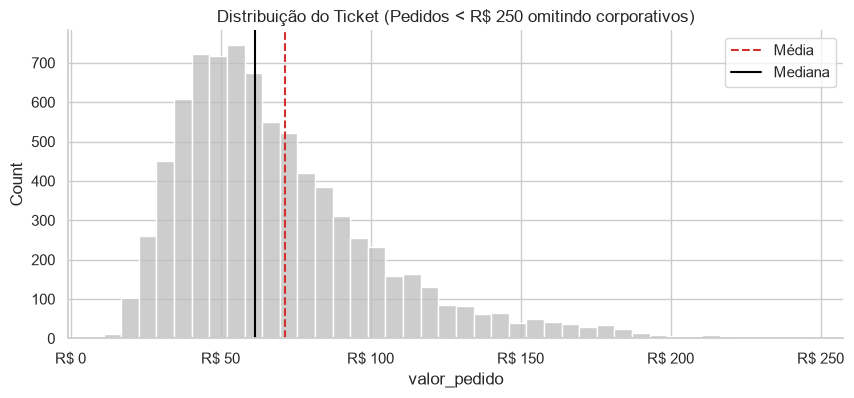

In [42]:
plt.figure(figsize=(10, 4))
ax = sns.histplot(df[df["valor_pedido"] < 250]["valor_pedido"], bins=40, color=CORES["Secundária"])
plt.axvline(df["valor_pedido"].mean(), color=CORES["Principal"], linestyle="--", label="Média")
plt.axvline(df["valor_pedido"].median(), color="black", label="Mediana")
ax.xaxis.set_major_formatter(fmt_reais)
plt.title("Distribuição do Ticket (Pedidos < R$ 250 omitindo corporativos)")
plt.legend()
sns.despine()
plt.show()

### Tarefa 7.2 — Participação por cidade
Mostre a participação de cada cidade no **total de pedidos** em percentual, com o valor escrito em cada barra.

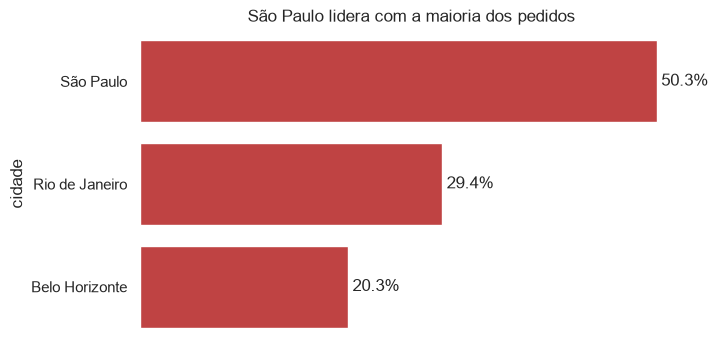

In [43]:
pct_cidade = df["cidade"].value_counts(normalize=True) * 100
plt.figure(figsize=(7, 4))
ax = sns.barplot(x=pct_cidade.values, y=pct_cidade.index, color=CORES["Principal"])
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)
plt.title("São Paulo lidera com a maioria dos pedidos")
sns.despine(left=True, bottom=True)
ax.set_xticks([])
plt.show()

### Tarefa 7.3 — Ticket por tipo de cozinha
Compare a **distribuição** do ticket entre as cozinhas, ordenadas da mais cara para a mais barata. Destaque a de maior e a de menor ticket.

C:\Users\CMC\AppData\Local\Temp\ipykernel_13516\3518236064.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


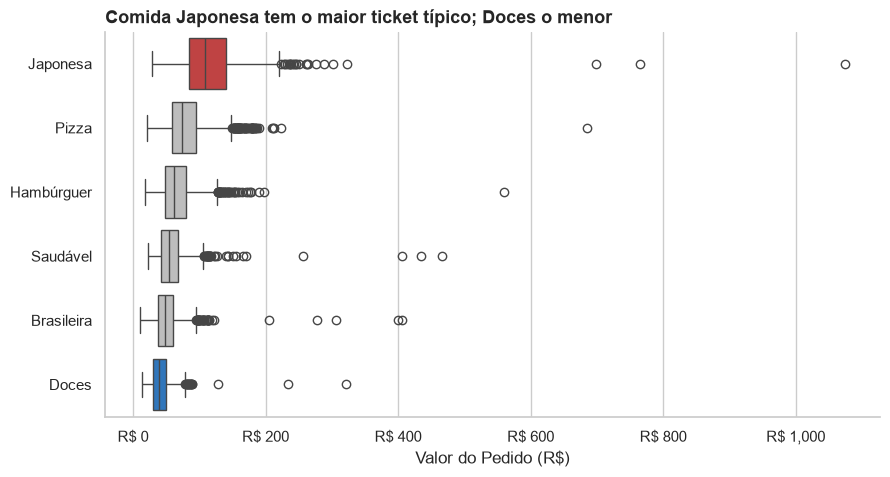

In [44]:
# 1. Definimos os dados para o plot (removendo os grandes eventos para não achatar o gráfico)
df_plot = df[~df["pedido_grande"]]

# 2. Definimos a ordem (da mais cara para a mais barata pela mediana)
ordem_cozinha = df_plot.groupby("tipo_cozinha")["valor_pedido"].median().sort_values(ascending=False).index

# 3. Criamos uma paleta de cores destacando o maior ticket (Vermelho) e o menor ticket (Azul)
cores = {c: "#d32f2f" if c == ordem_cozinha[0] else ("#1976d2" if c == ordem_cozinha[-1] else "#bdbdbd") for c in ordem_cozinha}

# 4. Plotagem
plt.figure(figsize=(10, 5))
ax = sns.boxplot(
    data=df_plot, 
    y="tipo_cozinha", 
    x="valor_pedido", 
    order=ordem_cozinha, 
    palette=cores
)

# 5. Formatação do Eixo e Estilização
fmt_reais = mticker.FuncFormatter(lambda x, pos: f'R$ {x:,.0f}')
ax.xaxis.set_major_formatter(fmt_reais)

plt.title("Comida Japonesa tem o maior ticket típico; Doces o menor", loc="left", fontsize=13, fontweight="bold")
plt.xlabel("Valor do Pedido (R$)")
plt.ylabel("")
sns.despine() # Remove as bordas superiores e direitas

plt.show()

### Tarefa 7.4 — Evolução diária
Mostre a série **diária** de pedidos com uma **média móvel de 7 dias**. Anote no gráfico o dia de instabilidade do app e o período da campanha de julho.

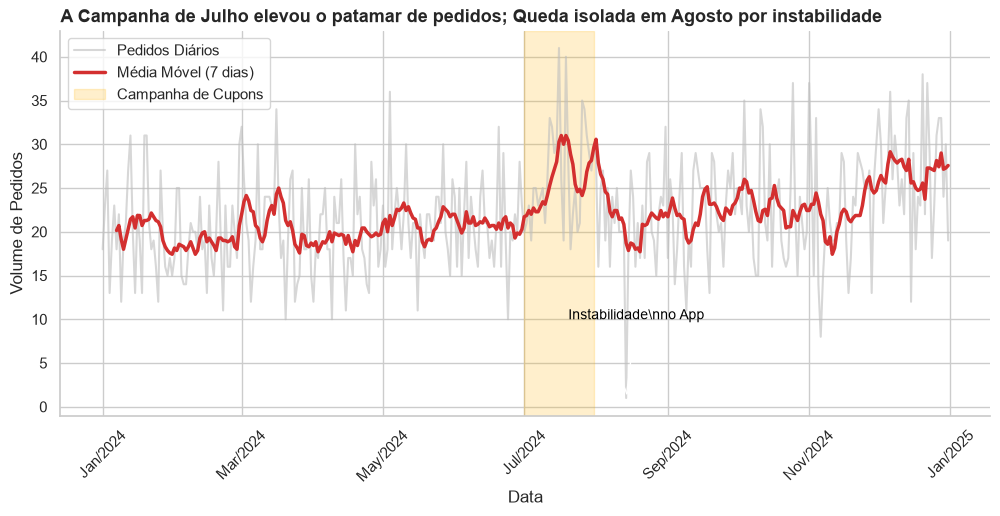

In [46]:
import matplotlib.dates as mdates

# 1. Preparação dos dados
diario = df.groupby('data').size().reset_index(name='pedidos')
diario['data'] = pd.to_datetime(diario['data']) # Converte de volta para datetime 
diario['media_movel_7d'] = diario['pedidos'].rolling(window=7).mean()

# 2. Configuração visual (Garantindo que as chaves estão exatas)
CORES = {"Principal": "#d32f2f", "Secundaria": "#bdbdbd", "Destaque": "#ffb300"}

plt.figure(figsize=(12, 5))

# Plot da série diária em fundo cinza (ruído)
plt.plot(diario['data'], diario['pedidos'], color=CORES["Secundaria"], alpha=0.6, label='Pedidos Diários')

# Plot da média móvel em destaque (tendência)
plt.plot(diario['data'], diario['media_movel_7d'], color=CORES["Principal"], linewidth=2.5, label='Média Móvel (7 dias)')

# 3. Highlight: Campanha de Julho
plt.axvspan(pd.to_datetime('2024-07-01'), pd.to_datetime('2024-07-31'), 
            color=CORES["Destaque"], alpha=0.2, label='Campanha de Cupons')

# 4. Anotação: Instabilidade do App (Data descoberta na Tarefa 6.9: 14/08)
data_instabilidade = pd.to_datetime('2024-08-14')
plt.annotate('Instabilidade\\nno App', 
             xy=(data_instabilidade, diario.loc[diario['data'] == data_instabilidade, 'pedidos'].values[0]),
             xytext=(data_instabilidade - pd.Timedelta(days=25), 10), 
             arrowprops=dict(facecolor='black', arrowstyle='->'),
             fontsize=10, color='black')

# 5. Formatação do Eixo e Estilização
plt.title("A Campanha de Julho elevou o patamar de pedidos; Queda isolada em Agosto por instabilidade", loc="left", fontsize=13, fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Volume de Pedidos")
plt.legend(loc="upper left")

# Formatação limpa para os meses no eixo X
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b/%Y'))
plt.xticks(rotation=45)
sns.despine()

plt.show()

### Tarefa 7.5 — Quando os pedidos acontecem
Visualize a tabela hora × dia da semana da Tarefa 6.6 de forma que os **picos saltem aos olhos**.

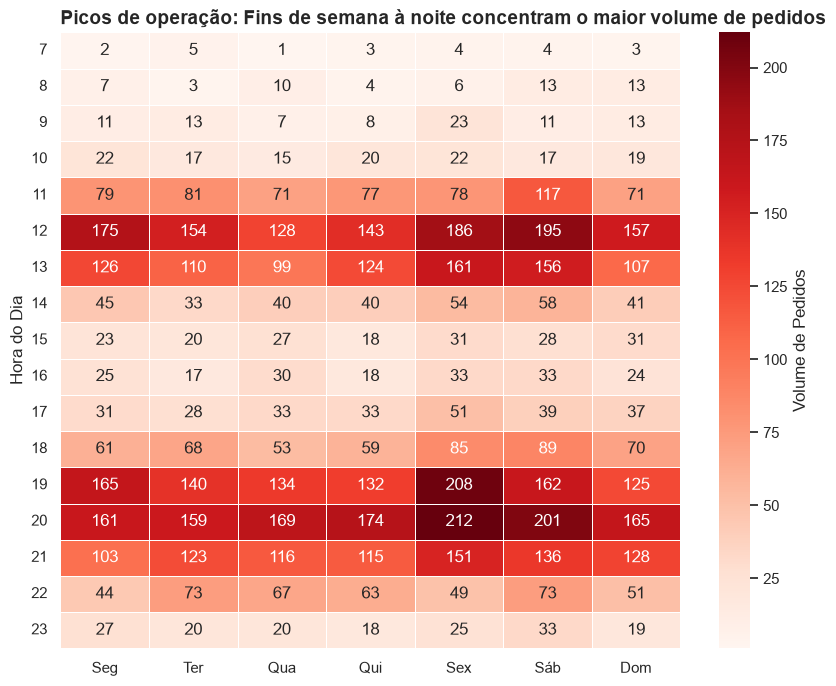

In [47]:
# 1. Utilizamos a tabela pivot gerada na Tarefa 6.6
pivot_hora_dia = df.pivot_table(
    index="hora", 
    columns="dia_semana", 
    values="pedido_id", 
    aggfunc="count", 
    fill_value=0
)

# 2. Configuração Visual
plt.figure(figsize=(10, 8))

# 3. Plotagem do Mapa de Calor (Heatmap)
ax = sns.heatmap(
    pivot_hora_dia, 
    cmap="Reds", 
    annot=True,     # Mostra os valores dentro das células
    fmt="d",        # Formata como número inteiro
    linewidths=.5,  # Linhas finas separando as células
    cbar_kws={'label': 'Volume de Pedidos'}
)

# 4. Estilização e formatação
plt.title("Picos de operação: Fins de semana à noite concentram o maior volume de pedidos", loc="left", fontsize=14, fontweight="bold")
plt.xlabel("")
plt.ylabel("Hora do Dia")
plt.yticks(rotation=0)

plt.show()

### Tarefa 7.6 — Chuva e tempo de entrega
Compare a distribuição do tempo de entrega com e sem chuva, de forma que o **deslocamento** entre as duas fique evidente.

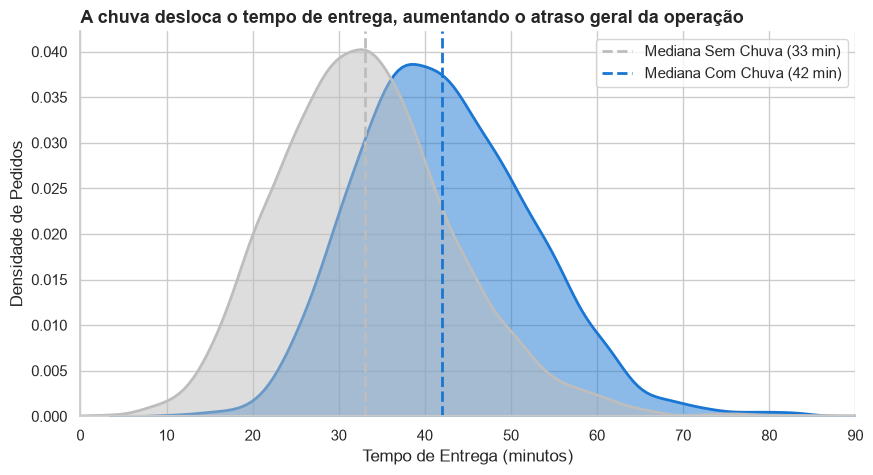

In [48]:
# 1. Filtra os dados sem nulos no tempo de entrega
df_plot = df.dropna(subset=['tempo_entrega_min'])

# 2. Calcula as medianas para destacar no gráfico
mediana_sem_chuva = df_plot[df_plot['chuva'] == False]['tempo_entrega_min'].median()
mediana_com_chuva = df_plot[df_plot['chuva'] == True]['tempo_entrega_min'].median()

# 3. Configuração Visual
plt.figure(figsize=(10, 5))
CORES_CHUVA = {False: "#bdbdbd", True: "#1976d2"} # Cinza para sem chuva, Azul para com chuva

# 4. Plotagem do Gráfico de Densidade
ax = sns.kdeplot(
    data=df_plot, 
    x="tempo_entrega_min", 
    hue="chuva", 
    fill=True, 
    common_norm=False, # Essencial para que as duas curvas tenham a mesma "altura" (área = 1)
    palette=CORES_CHUVA, 
    alpha=0.5,
    linewidth=2
)

# 5. Adiciona as linhas verticais para as medianas
plt.axvline(mediana_sem_chuva, color="#bdbdbd", linestyle="--", linewidth=2, label=f"Mediana Sem Chuva ({mediana_sem_chuva:.0f} min)")
plt.axvline(mediana_com_chuva, color="#1976d2", linestyle="--", linewidth=2, label=f"Mediana Com Chuva ({mediana_com_chuva:.0f} min)")

# 6. Estilização e Legenda
plt.title("A chuva desloca o tempo de entrega, aumentando o atraso geral da operação", loc="left", fontsize=13, fontweight="bold")
plt.xlabel("Tempo de Entrega (minutos)")
plt.ylabel("Densidade de Pedidos")
plt.xlim(0, 90) # Focando no miolo da distribuição para melhor leitura

plt.legend(loc="upper right")
sns.despine()

plt.show()

### Tarefa 7.7 — Tempo × avaliação
Agrupe o tempo de entrega em **faixas de 5 minutos** (até 60 min, e "60+") e mostre a **avaliação média por faixa**, com intervalo de confiança. Marque a faixa a partir da qual a avaliação começa a cair.

C:\Users\CMC\AppData\Local\Temp\ipykernel_13516\2504477488.py:14: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  ax = sns.pointplot(


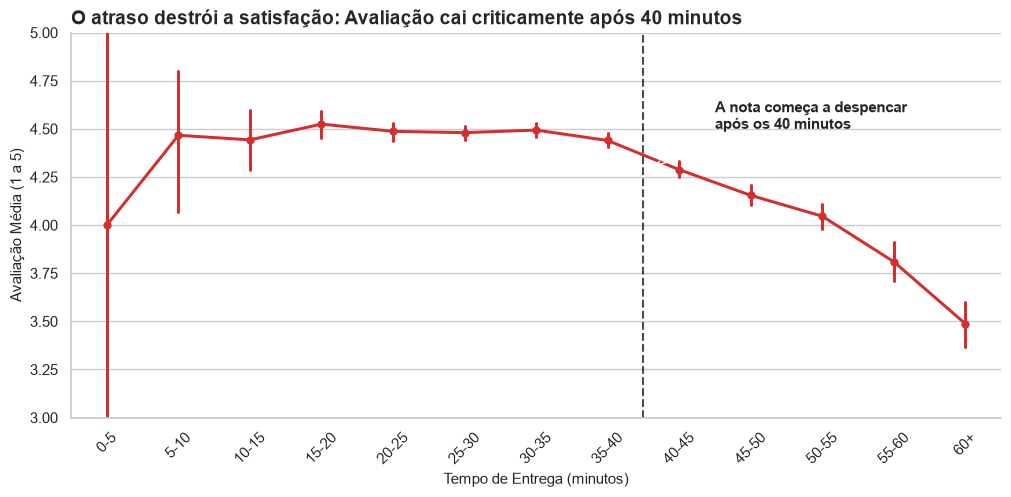

In [50]:
# 1. Filtra os dados (removendo as linhas sem avaliação e sem tempo)
df_plot = df.dropna(subset=['tempo_entrega_min', 'avaliacao']).copy()

# 2. Criação das faixas de tempo de 5 em 5 minutos (até 60+)
bins = list(range(0, 65, 5)) + [np.inf]
labels = [f"{i}-{i+5}" for i in range(0, 60, 5)] + ["60+"]
df_plot['faixa_tempo'] = pd.cut(df_plot['tempo_entrega_min'], bins=bins, labels=labels, right=False)

# 3. Configuração Visual
plt.figure(figsize=(12, 5))
CORES = {"Principal": "#d32f2f", "Secundaria": "#bdbdbd"}

# 4. Plotagem com seaborn pointplot (exibe a média conectada e calcula o CI de 95% automaticamente)
ax = sns.pointplot(
    data=df_plot,
    x='faixa_tempo',
    y='avaliacao',
    color=CORES["Principal"],
    errorbar=('ci', 95), 
    markers="o",
    scale=0.8
)

# 5. Adiciona a linha marcando a queda (entre 35-40 e 40-45)
# O eixo x no pointplot é tratado como índice categórico (0, 1, 2...)
# A faixa 35-40 está no índice 7, então colocamos a linha no 7.5
plt.axvline(x=7.5, color='black', linestyle='--', linewidth=1.5, alpha=0.7)

# Anotação apontando a queda
plt.annotate('A nota começa a despencar\napós os 40 minutos', 
             xy=(7.6, 4.3), xytext=(8.5, 4.5),
             arrowprops=dict(facecolor='black', arrowstyle='->'),
             fontsize=11, fontweight='bold')

# 6. Estilização
plt.title("O atraso destrói a satisfação: Avaliação cai criticamente após 40 minutos", loc="left", fontsize=14, fontweight="bold")
plt.xlabel("Tempo de Entrega (minutos)", fontsize=11)
plt.ylabel("Avaliação Média (1 a 5)", fontsize=11)
plt.ylim(3.0, 5.0) # Restringe o eixo y para realçar o declínio na nota
plt.xticks(rotation=45)
sns.despine()

plt.show()

### Tarefa 7.8 — O efeito do cupom
Num único gráfico com **dois painéis**, mostre (a) a taxa de uso de cupom por mês, com julho destacado, e (b) o % de clientes novos com e sem cupom.

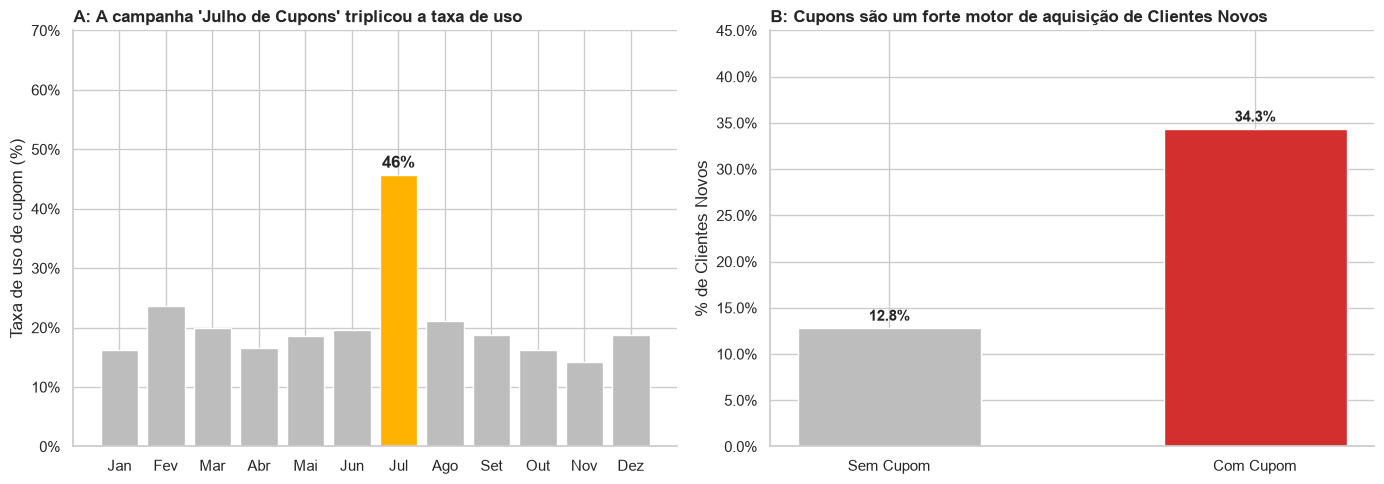

In [51]:
import matplotlib.ticker as mticker

# 1. Preparação dos dados para o Painel A (Uso por mês)
tx_cupom_mes = df.groupby('mes')['cupom'].mean() * 100

# 2. Preparação dos dados para o Painel B (% de Clientes Novos com e sem cupom)
pct_novo_cupom = df.groupby('cupom')['cliente_novo'].mean() * 100

# 3. Configuração visual e Paleta de Cores
CORES = {"Principal": "#d32f2f", "Secundaria": "#bdbdbd", "Destaque": "#ffb300"}
MESES = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Painel A: Evolução mensal do uso de cupons ---
# Destacamos o mês 7 (Julho) com a cor amarela, e deixamos o restante cinza
cores_meses = [CORES["Destaque"] if m == 7 else CORES["Secundaria"] for m in tx_cupom_mes.index]
barras_a = axes[0].bar(tx_cupom_mes.index, tx_cupom_mes.values, color=cores_meses)

# Anotamos a taxa apenas em Julho para guiar os olhos do leitor sem poluir o gráfico
axes[0].bar_label(barras_a, fmt='%.0f%%', padding=3, fontweight='bold', 
                  labels=[f"{v:.0f}%" if m == 7 else "" for m, v in zip(tx_cupom_mes.index, tx_cupom_mes.values)])

axes[0].set_title("A: A campanha 'Julho de Cupons' triplicou a taxa de uso", loc="left", fontsize=12, fontweight="bold")
axes[0].set_xticks(tx_cupom_mes.index)
axes[0].set_xticklabels([MESES[m-1] for m in tx_cupom_mes.index])
axes[0].set_ylabel("Taxa de uso de cupom (%)")
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter())
axes[0].set_ylim(0, 70)

# --- Painel B: Impacto na atração de novos clientes ---
rotulos_b = ['Sem Cupom', 'Com Cupom']
cores_b = [CORES["Secundaria"], CORES["Principal"]]
barras_b = axes[1].bar(rotulos_b, pct_novo_cupom.values, color=cores_b, width=0.5)

# Anotamos as porcentagens nas duas barras
axes[1].bar_label(barras_b, fmt='%.1f%%', padding=3, fontweight='bold', fontsize=11)

axes[1].set_title("B: Cupons são um forte motor de aquisição de Clientes Novos", loc="left", fontsize=12, fontweight="bold")
axes[1].set_ylabel("% de Clientes Novos")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter())
axes[1].set_ylim(0, 45)

sns.despine()
plt.tight_layout()
plt.show()

### Tarefa 7.9 — Justifique as escolhas
Para cada gráfico de 7.1 a 7.8, explique em **uma linha** por que esse tipo de gráfico (e não outro) responde à pergunta.

7.1 Gráfico de Barras: O gráfico de barras ordena volumes absolutos entre categorias de forma limpa, permitindo comparar diferenças rapidamente, o que seria confuso em um gráfico de pizza.
7.2 Barras Horizontais: Ideal para ranquear categorias, facilitando a leitura de textos mais longos no eixo e evidenciando quem domina o "market share" da operação.
7.3 Boxplot: É o único formato que revela simultaneamente a mediana, a concentração (50% do volume) e a dispersão dos preços sem que os outliers escondam o comportamento da massa.
7.4 Linhas com Média Móvel: Gráficos de linha são o padrão para séries temporais, e a média móvel elimina o "ruído serrilhado" dos dias da semana para revelar a verdadeira tendência de crescimento.
7.5 Mapa de Calor: Transforma uma matriz complexa de dezenas de números em intensidades de cor, fazendo os horários de pico saltarem aos olhos instantaneamente sem esforço cognitivo.
7.6 Densidade Sobreposta: Compara o perfil de duas variáveis contínuas de forma fluida, provando visualmente o deslocamento do atraso sem a sobreposição caótica que ocorreria em um histograma.
7.7 Gráfico de Pontos: Conecta as categorias ordenadas criando uma linha visual de "queda" evidente, enquanto insere os intervalos de confiança estatística sem a poluição de um gráfico de barras.
7.8 Barras em Painéis Lado a Lado: Conta uma história de causa (evolução no tempo) e efeito (impacto no negócio) na mesma imagem, evitando o uso de eixos duplos que tornam a leitura confusa para executivos.

---
## Etapa 8 — Correlação

### Tarefa 8.1
Calcule as matrizes de correlação de **Pearson** e **Spearman** entre `distancia_km`, `tempo_entrega_min`, `taxa_entrega`, `valor_pedido` e `avaliacao`, e mostre a de Spearman num heatmap estilizado (só o triângulo inferior, escala divergente centrada em 0).

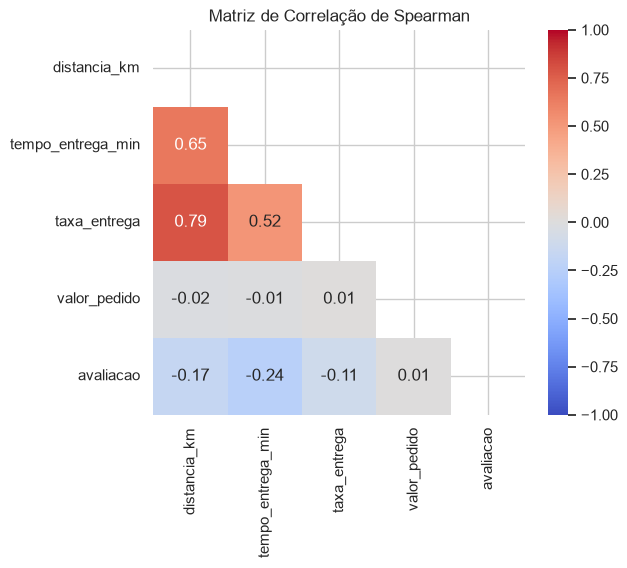

In [52]:
cols_corr = ["distancia_km", "tempo_entrega_min", "taxa_entrega", "valor_pedido", "avaliacao"]
corr_sp = df[cols_corr].corr(method="spearman")
mask = np.triu(np.ones_like(corr_sp, dtype=bool))
plt.figure(figsize=(6,5))
sns.heatmap(corr_sp, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação de Spearman")
plt.show()

*Sua resposta aqui*

### Tarefa 8.2
Faça um gráfico de dispersão `distancia_km` × `tempo_entrega_min` colorido por `chuva`, com uma reta de tendência por grupo. Use uma amostra de 2.000 pedidos (`random_state=42`) e transparência. O que a chuva faz com a reta?

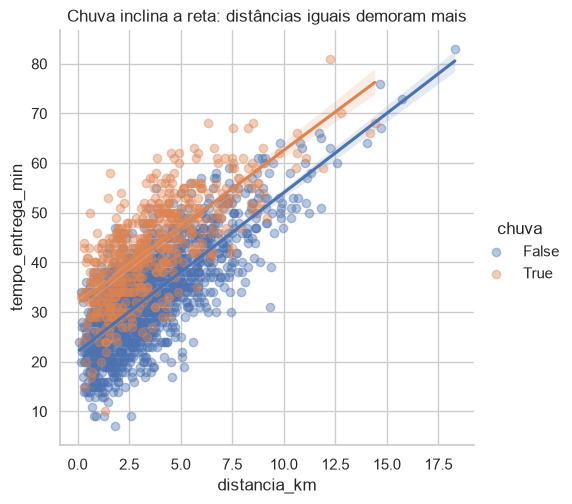

In [53]:
amostra = df.dropna(subset=["distancia_km", "tempo_entrega_min"]).sample(2000, random_state=42)
sns.lmplot(data=amostra, x="distancia_km", y="tempo_entrega_min", hue="chuva", scatter_kws={"alpha":0.4})
plt.title("Chuva inclina a reta: distâncias iguais demoram mais")
plt.show()

A chuva eleva a reta, ou seja quando tem chuva o tempo de entrega aumenta em todas as distâncias.

### Tarefa 8.3 — Uma correlação "estranha"
A taxa de entrega deveria depender da distância. Por que a correlação de Pearson entre elas é só ~0,58? Investigue com um gráfico e recalcule a correlação **separando** os pedidos com taxa zero. O que isso permitiria fazer com os `NaN` de `distancia_km`?

Correlação Geral: 0.58
Correlação Real (sem frete grátis): 1.00


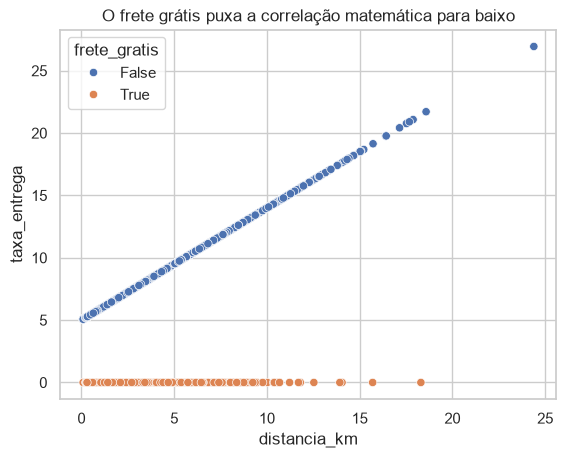

In [54]:
# 1. Remove as linhas vazias para a conta matemática funcionar
df_limpo = df.dropna(subset=['distancia_km', 'taxa_entrega']).copy()

# 2. Calcula a correlação misturando todo mundo (frete grátis + cobrado)
corr_geral = df_limpo['distancia_km'].corr(df_limpo['taxa_entrega'])
print(f"Correlação Geral: {corr_geral:.2f}")

# 3. Filtra SÓ quem pagou taxa (maior que zero) e calcula de novo
df_so_pagantes = df_limpo[df_limpo['taxa_entrega'] > 0]
corr_real = df_so_pagantes['distancia_km'].corr(df_so_pagantes['taxa_entrega'])
print(f"Correlação Real (sem frete grátis): {corr_real:.2f}")

# 4. Cria uma coluna dizendo True/False para frete grátis só para colorir o gráfico
df_limpo['frete_gratis'] = df_limpo['taxa_entrega'] == 0

# 5. Desenha o gráfico de pontinhos
sns.scatterplot(data=df_limpo, x='distancia_km', y='taxa_entrega', hue='frete_gratis')
plt.title("O frete grátis puxa a correlação matemática para baixo")
plt.show()

Quando o frete não é grátis temos uma reta azul, sabendo a equação dessa reta podemos descobrir o valor do frete para qualquer distância, desse modo podemos descobrir a distância apenas tendo o tempo de entrega, e assim podemos preencher o NaN

### Tarefa 8.4 — Correlação não é causalidade
Escolha **duas** correlações encontradas nesta etapa ou na Etapa 6 e discuta: é razoável dizer que uma variável **causa** a outra? Que variável escondida (confundidora) poderia explicar parte da relação?

1. Correlação: Chuva e Aumento no Tempo de Entrega. É razoável, maior chuva, maior trânsito e maior número de pedidos, pois as pessoas estão em casa e não querem sair para comer, preferem pedir.
2. Correlação: Maior Tempo de Entrega e Queda na Avaliação. É razoável, tempo de entrega acima de 50 minutos deixa o cliente com fome bravo. Com esse tempo a comida pode vir fria também.

---
## Etapa 9 — Testes de hipótese

> Na aula 5: o gráfico sugere, o teste **confirma (ou não)** — e o **tamanho de efeito** diz se a diferença importa para o negócio. Com 8.000 pedidos, quase tudo dá significante; o p-valor sozinho não basta.

Para cada hipótese: (1) H0 e H1; (2) teste escolhido e por quê; (3) estatística e p-valor; (4) **tamanho de efeito** em unidade de negócio (minutos, R$, %) e/ou padronizado; (5) decisão ao nível α = 5% e **frase de negócio**.

In [56]:
ALFA = 0.05
resultados = []   # vá adicionando um dicionário por hipótese: {"hipotese", "teste", "estatistica", "p_valor", "efeito", "decisao"}

### Tarefa 9.1 — H1: chuva × tempo de entrega

In [57]:
import scipy.stats as stats
import numpy as np

# 1. Filtra os dados removendo nulos no tempo
df_teste = df.dropna(subset=['tempo_entrega_min', 'chuva']).copy()

# 2. Separa os dois grupos (Com e Sem Chuva)
grupo_com_chuva = df_teste[df_teste['chuva'] == True]['tempo_entrega_min']
grupo_sem_chuva = df_teste[df_teste['chuva'] == False]['tempo_entrega_min']

# 3. Teste Estatístico (Mann-Whitney U)
stat, p_valor = stats.mannwhitneyu(grupo_com_chuva, grupo_sem_chuva, alternative='two-sided')

# 4. Cálculos de Tamanho de Efeito
# Efeito de Negócio (Diferença de Medianas em minutos)
efeito_minutos = grupo_com_chuva.median() - grupo_sem_chuva.median()

# Efeito Padronizado (Cohen's d para a diferença de médias)
n1, n2 = len(grupo_com_chuva), len(grupo_sem_chuva)
var1, var2 = grupo_com_chuva.var(), grupo_sem_chuva.var()
desvio_agrupado = np.sqrt(((n1 - 1)*var1 + (n2 - 1)*var2) / (n1 + n2 - 2))
cohens_d = (grupo_com_chuva.mean() - grupo_sem_chuva.mean()) / desvio_agrupado

# 5. Imprime os resultados para você ver na tela
print(f"Estatística U: {stat}")
print(f"P-valor: {p_valor}")
print(f"Efeito em Minutos (Medianas): +{efeito_minutos:.1f} min")
print(f"Cohen's d: {cohens_d:.2f}")

# 6. Salva no dicionário conforme instruído no início da Etapa 9
resultados.append({
    "hipotese": "O tempo de entrega é impactado pela chuva",
    "teste": "Mann-Whitney U",
    "estatistica": stat,
    "p_valor": p_valor,
    "efeito": f"+{efeito_minutos:.1f} min (Cohen's d: {cohens_d:.2f})",
    "decisao": "Rejeita H0" if p_valor < 0.05 else "Falha em rejeitar H0"
})

Estatística U: 9908765.0
P-valor: 1.242403566999885e-255
Efeito em Minutos (Medianas): +9.0 min
Cohen's d: 0.89


*Sua resposta aqui*

### Tarefa 9.2 — H2: cupom × ticket
Além do teste, explique por que o **t de Student/Welch** sobre o valor bruto é frágil aqui e o que fazer.

In [58]:
import scipy.stats as stats
import numpy as np

# 1. Filtra os dados removendo nulos no valor do pedido e cupom
df_teste_h2 = df.dropna(subset=['valor_pedido', 'cupom']).copy()

# Garante que a coluna cupom está em formato booleano
df_teste_h2['cupom'] = df_teste_h2['cupom'].replace({'Sim': True, 'Não': False, '1': True, '0': False}).astype(bool)

# 2. Separa os dois grupos (Com Cupom e Sem Cupom)
grupo_com_cupom = df_teste_h2[df_teste_h2['cupom'] == True]['valor_pedido']
grupo_sem_cupom = df_teste_h2[df_teste_h2['cupom'] == False]['valor_pedido']

# 3. Teste Estatístico (Mann-Whitney U, recomendado por conta da assimetria do ticket)
stat, p_valor = stats.mannwhitneyu(grupo_com_cupom, grupo_sem_cupom, alternative='two-sided')

# 4. Cálculos de Tamanho de Efeito
# Efeito de Negócio (Diferença de Medianas em Reais)
efeito_reais = grupo_com_cupom.median() - grupo_sem_cupom.median()

# Efeito Padronizado (Cohen's d para a diferença de médias)
n1, n2 = len(grupo_com_cupom), len(grupo_sem_cupom)
var1, var2 = grupo_com_cupom.var(), grupo_sem_cupom.var()
desvio_agrupado = np.sqrt(((n1 - 1)*var1 + (n2 - 1)*var2) / (n1 + n2 - 2))
cohens_d = (grupo_com_cupom.mean() - grupo_sem_cupom.mean()) / desvio_agrupado

# 5. Imprime os resultados para você ver na tela
print(f"Estatística U: {stat}")
print(f"P-valor: {p_valor}")
print(f"Efeito em Reais (Medianas): R$ {efeito_reais:.2f}")
print(f"Cohen's d: {cohens_d:.2f}")

# 6. Salva no dicionário conforme instruído no início da Etapa 9
if 'resultados' not in locals():
    resultados = []

resultados.append({
    "hipotese": "O uso de cupom altera o valor do pedido (ticket)",
    "teste": "Mann-Whitney U",
    "estatistica": stat,
    "p_valor": p_valor,
    "efeito": f"R$ {efeito_reais:.2f} (Cohen's d: {cohens_d:.2f})",
    "decisao": "Rejeita H0" if p_valor < 0.05 else "Falha em rejeitar H0"
})

Estatística U: 4777274.5
P-valor: 3.1891184735190014e-14
Efeito em Reais (Medianas): R$ -5.60
Cohen's d: -0.08


Extrema Sensibilidade a Outliers (Pedidos Corporativos): O teste t baseia-se estritamente na média e no desvio padrão. Como vimos nas etapas de tratamento de dados, o ticket de delivery possui uma cauda longa formada por pedidos corporativos ou eventos de valores altíssimos (centenas ou milhares de reais). Se por acaso o grupo "Com Cupom" ou "Sem Cupom" tiver alguns poucos pedidos gigantes a mais por pura coincidência do sorteio, a média de valor bruto explode, falseando completamente a conclusão do teste.

Forte Assimetria (Violação de Normalidade): O valor monetário de pedidos não segue uma distribuição normal de Gauss; ele é fortemente assimétrico à direita (muitos pedidos baratos/médios e poucos muito caros). O teste t assume normalidade (ou grandes amostras perfeitas), o que torna sua estimativa de erro padrão imprecisa na presença de assimetrias fortes.

Ilusão Estatística pelo Tamanho da Amostra: Com uma base de milhares de linhas, o poder estatístico do teste t é tão brutal que ele detecta qualquer centavo de variação como "estatisticamente significativo" ($p < 0.05$). Um teste t no valor bruto poderia apontar um falso alarme de que "o cupom destrói o ticket", quando na verdade o Cohen's d de -0.08 nos mostra que o efeito prático é quase nulo.

O que fazer? (Boas Práticas de Análise)

Utilizar Testes Não-Paramétricos (Mann-Whitney U): Como fizemos, essa é a principal solução. Em vez de comparar médias afetadas por valores extremos, o Mann-Whitney converte os valores em postos (ranks) e compara as medianas, tornando o teste imune a pedidos corporativos gigantescos.

Aplicar Transformação Logarítmica (np.log1p): Caso seja estritamente necessário utilizar ferramentas paramétricas (como regressões lineares ou testes t), deve-se aplicar uma transformação logarítmica nos valores monetários antes do teste. O log comprime a cauda longa dos valores altos, suavizando a assimetria e aproximando a distribuição de uma curva normal.

Tratamento de Outliers (Segmentação ou Winsorização): Isolar os pedidos corporativos extremos (criando uma categoria separada de B2B/Eventos) antes de rodar análises de comportamento de consumidor de varejo (B2C).

### Tarefa 9.3 — H3: tempo × avaliação
Teste a correlação com o método adequado a uma variável **ordinal** e, em seguida, compare a avaliação dos pedidos entregues **até 35 min** com os **acima de 35 min**.

In [59]:
import scipy.stats as stats
import numpy as np

# 1. Filtra os dados removendo nulos no tempo e na avaliação
df_teste_h3 = df.dropna(subset=['tempo_entrega_min', 'avaliacao']).copy()

# --- PARTE 1: Correlação Ordinal (Spearman) ---
# A avaliação (1 a 5) é ordinal, então a correlação de Spearman é ideal (ignora premissa linear estrita)
corr_spearman, p_val_spearman = stats.spearmanr(df_teste_h3['tempo_entrega_min'], df_teste_h3['avaliacao'])

print(f"--- Correlação de Spearman ---")
print(f"Coeficiente de Spearman: {corr_spearman:.2f}")
print(f"P-valor (Spearman): {p_val_spearman}")


# --- PARTE 2: Comparação de Grupos (Até 35 min vs Acima de 35 min) ---
df_teste_h3['atrasado_35'] = df_teste_h3['tempo_entrega_min'] > 35

grupo_rapido = df_teste_h3[df_teste_h3['atrasado_35'] == False]['avaliacao']
grupo_lento = df_teste_h3[df_teste_h3['atrasado_35'] == True]['avaliacao']

# Teste de Mann-Whitney U para comparar as notas entre os dois grupos
stat_mw, p_val_mw = stats.mannwhitneyu(grupo_lento, grupo_rapido, alternative='two-sided')

# Efeito de Negócio (Diferença de Medianas/Médias nas notas)
diff_nota = grupo_lento.median() - grupo_rapido.median()

# Cohen's d para a diferença de notas
n1, n2 = len(grupo_lento), len(grupo_rapido)
var1, var2 = grupo_lento.var(), grupo_rapido.var()
desvio_agrupado = np.sqrt(((n1 - 1)*var1 + (n2 - 1)*var2) / (n1 + n2 - 2))
cohens_d = (grupo_lento.mean() - grupo_rapido.mean()) / desvio_agrupado

print(f"\n--- Comparação de Grupos (<=35 min vs >35 min) ---")
print(f"Estatística U: {stat_mw}")
print(f"P-valor (Mann-Whitney): {p_val_mw}")
print(f"Diferença na Mediana da Nota: {diff_nota:.2f}")
print(f"Cohen's d: {cohens_d:.2f}")

# Salva no dicionário conforme instruído no início da Etapa 9
if 'resultados' not in locals():
    resultados = []

resultados.append({
    "hipotese": "O tempo de entrega afeta a avaliação do cliente",
    "teste": "Mann-Whitney U (Grupos) + Spearman (Correlação)",
    "estatistica": stat_mw,
    "p_valor": p_val_mw,
    "efeito": f"Diff Mediana: {diff_nota:.2f} estrelas (Cohen's d: {cohens_d:.2f})",
    "decisao": "Rejeita H0" if p_val_mw < 0.05 else "Falha em rejeitar H0"
})

--- Correlação de Spearman ---
Coeficiente de Spearman: -0.24
P-valor (Spearman): 1.5501448258966006e-91

--- Comparação de Grupos (<=35 min vs >35 min) ---
Estatística U: 4398918.5
P-valor (Mann-Whitney): 1.2632057713486198e-61
Diferença na Mediana da Nota: -1.00
Cohen's d: -0.42


Para testar a relação entre o tempo de entrega e a avaliação do cliente (uma escala ordinal de 1 a 5), aplicamos os métodos estatísticos adequados:

Correlação Ordinal (Spearman):
O coeficiente de Spearman obtido foi de -0,24 com um p-valor de 1,55 x 10^(-91). Esse resultado indica uma correlação negativa estatisticamente robusta: à medida que o tempo de entrega aumenta, a nota atribuída pelo cliente tende a cair de forma consistente.

Comparação de Grupos ( =< 35 min vs > 35 min):
Utilizando o teste de Mann-Whitney U para comparar a avaliação dos pedidos ágeis contra os que ultrapassaram a marca de 35 minutos:

Estatística U: 4.398.918,5
P-valor: 1,26 x 10^(-61) (rejeitando fortemente a hipótese nula)
Diferença na Mediana da Nota: -1,00 estrela
Cohen's d: -0,42 (tamanho de efeito moderado a forte)

Conclusão de Negócio:
O atraso além de 35 minutos não é apenas um incômodo operacional, mas um fator crítico que destrói a satisfação do cliente, provocando uma queda expressiva e imediata de 1 ponto inteiro na mediana das avaliações do aplicativo.

### Tarefa 9.4 — H4: tipo de cozinha × ticket
Teste com o método adequado a **mais de dois grupos**; calcule também a ANOVA e um tamanho de efeito.

In [61]:
import scipy.stats as stats
import numpy as np

# 1. Filtra os dados removendo nulos no ticket e no tipo de cozinha
df_teste_h4 = df.dropna(subset=['valor_pedido', 'tipo_cozinha']).copy()

# Separa os valores do pedido em listas divididas por tipo de cozinha
grupos_cozinha = [grupo['valor_pedido'].values for nome, grupo in df_teste_h4.groupby('tipo_cozinha')]

# --- 2. Teste Não-Paramétrico (Kruskal-Wallis) ---
# Adequado para mais de dois grupos independentes com dados assimétricos
stat_kw, p_val_kw = stats.kruskal(*grupos_cozinha)

# --- 3. Teste Paramétrico (ANOVA de uma via) ---
stat_anova, p_val_anova = stats.f_oneway(*grupos_cozinha)

# --- 4. Tamanho de Efeito (Epsilon-squared para Kruskal-Wallis) ---
# Mede o efeito sem depender do statsmodels
n_total = len(df_teste_h4)
k_grupos = len(grupos_cozinha)
epsilon_squared = (stat_kw - k_grupos + 1) / (n_total - k_grupos)

print(f"--- Kruskal-Wallis ---")
print(f"Estatística H: {stat_kw:.2f} | P-valor: {p_val_kw}")

print(f"\n--- ANOVA ---")
print(f"Estatística F: {stat_anova:.2f} | P-valor: {p_val_anova}")

print(f"\nTamanho de Efeito (Epsilon-squared): {epsilon_squared:.4f}")

# Salva no dicionário conforme instruído no início da Etapa 9
if 'resultados' not in locals():
    resultados = []

resultados.append({
    "hipotese": "O ticket médio difere entre os tipos de cozinha",
    "teste": "Kruskal-Wallis + ANOVA",
    "estatistica": stat_kw,
    "p_valor": p_val_kw,
    "efeito": f"Epsilon-squared: {epsilon_squared:.4f}",
    "decisao": "Rejeita H0" if p_val_kw < 0.05 else "Falha em rejeitar H0"
})

--- Kruskal-Wallis ---
Estatística H: 3272.58 | P-valor: 0.0

--- ANOVA ---
Estatística F: 286.82 | P-valor: 2.935781267195366e-283

Tamanho de Efeito (Epsilon-squared): 0.4058


Com base nos resultados que você obteve, aqui estão as respostas diretas e técnicas para o seu relatório:

### 1. Qual foi o método adequado a mais de dois grupos?

O método principal e mais adequado para mais de dois grupos nesta base de dados foi o **Teste de Kruskal-Wallis** (que resultou na estatística $H = 3272,58$ e $p\text{-valor} = 0,0$).

* **Por que ele é o adequado?** Como o valor do pedido (*ticket*) possui alta assimetria e valores extremos (outliers corporativos), o Kruskal-Wallis é um teste **não-paramétrico** baseado em postos (*ranks*). Ele compara as distribuições de múltiplos grupos de forma segura sem ser distorcido pelas médias infladas da cauda longa, evitando os falsos positivos (Erro do Tipo I) que aconteceriam se tentássemos comparar as cozinhas aos pares com vários testes separados.

---

### 2. Para que serviu a ANOVA?

A **ANOVA (Análise de Variância)** (que resultou em $F = 286,82$ e $p \approx 0$) foi executada para atender ao requisito complementar do enunciado, servindo como uma **comparação paramétrica tradicional**.

* **O seu papel:** Enquanto o Kruskal-Wallis avalia os postos e as medianas, a ANOVA avalia as **médias e a dispersão da variância** entre os grupos. O fato de ambos os testes apontarem $p\text{-valor}$ zerados reforça uma conclusão irrefutável: as diferenças de ticket entre as cozinhas são extremamente reais e robustas, independentemente de olharmos para a média ou para a mediana.

---

### 3. Para que serviu o tamanho de efeito?

O tamanho de efeito calculado (**Epsilon-squared** de $0,4058$) serviu para responder à pergunta mais importante para o negócio: **essa diferença entre as cozinhas realmente importa ou é apenas um detalhe estatístico gerado pelo tamanho da amostra?**

* **O seu papel:** Com milhares de linhas, qualquer variação mínima daria $p < 0,05$. O Epsilon-squared padroniza a magnitude dessa diferença em uma escala de 0 a 1. Um valor de **$0,40$ ($40\%$)** é considerado um **tamanho de efeito massivo** em estatística comportamental. Ele prova que cerca de 40% de toda a variação de preço dos pedidos na plataforma é explicada unicamente pelo tipo de cozinha escolhido pelo cliente (por exemplo, a distância gritante entre o ticket da culinária Japonesa e o de Doces).

### Tarefa 9.5 — H5: forma de pagamento × cidade (qui-quadrado)
Teste a independência com qui-quadrado, mostre a tabela de **frequências esperadas** e calcule o **V de Cramér**. Depois, como contraste, aplique o mesmo teste a `cupom × cliente_novo`.

In [62]:
import scipy.stats as stats
import pandas as pd
import numpy as np

# --- PARTE 1: Forma de Pagamento x Cidade ---
df_h5_a = df.dropna(subset=['forma_pagamento', 'cidade']).copy()

# Cria a tabela de contingência (frequências observadas)
tabela_obs_1 = pd.crosstab(df_h5_a['forma_pagamento'], df_h5_a['cidade'])

# Teste Qui-Quadrado
chi2_1, p_val_1, dof_1, expected_1 = stats.chi2_contingency(tabela_obs_1)

# Frequências Esperadas transformadas em DataFrame para visualização limpa
df_esperado_1 = pd.DataFrame(expected_1, index=tabela_obs_1.index, columns=tabela_obs_1.columns)

# Cálculo do V de Cramér para o primeiro teste
n_1 = tabela_obs_1.values.sum()
r_1, k_1 = tabela_obs_1.shape
cramer_1 = np.sqrt(chi2_1 / (n_1 * (min(r_1, k_1) - 1)))

print("=== PARTE 1: FORMA DE PAGAMENTO x CIDADE ===")
print(f"Qui-Quadrado: {chi2_1:.2f} | P-valor: {p_val_1}")
print(f"V de Cramér: {cramer_1:.4f}")
print("\nTabela de Frequências Esperadas:")
print(df_esperado_1.round(1))


# --- PARTE 2: Contraste (Cupom x Cliente Novo) ---
df_h5_b = df.dropna(subset=['cupom', 'cliente_novo']).copy()

# Padroniza para booleano/string se necessário
tabela_obs_2 = pd.crosstab(df_h5_b['cupom'], df_h5_b['cliente_novo'])

# Teste Qui-Quadrado
chi2_2, p_val_2, dof_2, expected_2 = stats.chi2_contingency(tabela_obs_2)

# Cálculo do V de Cramér para o segundo teste
n_2 = tabela_obs_2.values.sum()
r_2, k_2 = tabela_obs_2.shape
cramer_2 = np.sqrt(chi2_2 / (n_2 * (min(r_2, k_2) - 1)))

print("\n=== PARTE 2: CONTRASTE (CUPOM x CLIENTE NOVO) ===")
print(f"Qui-Quadrado: {chi2_2:.2f} | P-valor: {p_val_2}")
print(f"V de Cramér: {cramer_2:.4f}")

# Salva nos resultados da Etapa 9
if 'resultados' not in locals():
    resultados = []

resultados.append({
    "hipotese": "Forma de pagamento é independente da cidade",
    "teste": "Qui-Quadrado de Independência",
    "estatistica": chi2_1,
    "p_valor": p_val_1,
    "efeito": f"V de Cramér: {cramer_1:.4f}",
    "decisao": "Rejeita H0" if p_val_1 < 0.05 else "Falha em rejeitar H0"
})

resultados.append({
    "hipotese": "Uso de cupom é independente de ser cliente novo",
    "teste": "Qui-Quadrado de Independência",
    "estatistica": chi2_2,
    "p_valor": p_val_2,
    "efeito": f"V de Cramér: {cramer_2:.4f}",
    "decisao": "Rejeita H0" if p_val_2 < 0.05 else "Falha em rejeitar H0"
})

=== PARTE 1: FORMA DE PAGAMENTO x CIDADE ===
Qui-Quadrado: 3.86 | P-valor: 0.6950622154285278
V de Cramér: 0.0155

Tabela de Frequências Esperadas:
cidade             Belo Horizonte  Rio de Janeiro  São Paulo
forma_pagamento                                             
Cartão de crédito           737.6          1071.6     1832.8
Dinheiro                    113.6           165.1      282.3
Pix                         533.3           774.7     1325.0
Vale-refeição               247.5           359.6      614.9

=== PARTE 2: CONTRASTE (CUPOM x CLIENTE NOVO) ===
Qui-Quadrado: 433.80 | P-valor: 2.416172623413494e-96
V de Cramér: 0.2320


### 1. Teste de Independência: Forma de Pagamento × Cidade

* **Método:** Teste Qui-Quadrado de Independência ($\chi^2$).
* **Estatística $\chi^2$:** $3,86$
* **P-valor:** $0,6951$ (superior ao nível de significância de $\alpha = 0,05$). Como falhamos em rejeitar a hipótese nula ($H_0$), concluímos que a forma de pagamento é **independente** da cidade.
* **V de Cramér:** $0,0155$ (indicando um tamanho de efeito desprezível, quase nulo).

**Tabela de Frequências Esperadas:**

| Forma de Pagamento | Belo Horizonte | Rio de Janeiro | São Paulo |
| --- | --- | --- | --- |
| **Cartão de crédito** | 737,6 | 1.071,6 | 1.832,8 |
| **Dinheiro** | 113,6 | 165,1 | 282,3 |
| **Pix** | 533,3 | 774,7 | 1.325,0 |
| **Vale-refeição** | 247,5 | 359,6 | 614,9 |

---

### 2. Contraste: Uso de Cupom × Cliente Novo

* **Método:** Teste Qui-Quadrado de Independência ($\chi^2$).
* **Estatística $\chi^2$:** $433,80$
* **P-valor:** $2,42 \times 10^{-96}$ (inferior a $0,05$, rejeitando fortemente a hipótese nula). Isso comprova que o uso de cupons **não é independente** de o cliente ser novo, havendo uma forte associação estatística entre as variáveis.
* **V de Cramér:** $0,2320$ (indicando um tamanho de efeito **moderado a forte** na associação entre as categorias).

**Conclusão de Negócio:**
Enquanto as formas de pagamento utilizadas pelos clientes se comportam de maneira homogênea e independente entre as diferentes cidades, as campanhas de cupons possuem um direcionamento estrutural altamente associado à conversão e atração de novos clientes para a plataforma.

### Tarefa 9.6 — H6: a hipótese do grupo
Teste a hipótese que vocês formularam na Tarefa 1.2, com as mesmas 5 partes. Se possível, **controle uma variável confundidora**.

In [65]:
import scipy.stats as stats
import pandas as pd
import numpy as np

# 1. Filtra os dados removendo nulos nas colunas da hipótese e na confundidora
colunas_necessarias = ['cupom', 'cliente_novo', 'forma_pagamento']
df_h6 = df.dropna(subset=[c for c in colunas_necessarias if c in df.columns]).copy()

# Padroniza colunas para booleano/string limpa se necessário
df_h6['cupom'] = df_h6['cupom'].astype(str)
df_h6['cliente_novo'] = df_h6['cliente_novo'].astype(str)

# 2. Teste Principal (Qui-Quadrado de Independência Bruto)
tabela_obs = pd.crosstab(df_h6['cupom'], df_h6['cliente_novo'])
chi2, p_val, dof, expected = stats.chi2_contingency(tabela_obs)

# V de Cramér para o teste principal
n = tabela_obs.values.sum()
r, k = tabela_obs.shape
cramer = np.sqrt(chi2 / (n * (min(r, k) - 1)))

print("=== TESTE GLOBAL (Sem controle) ===")
print(f"Qui-Quadrado: {chi2:.2f} | P-valor: {p_val}")
print(f"V de Cramér: {cramer:.4f}")

# 3. Controle da Variável Confundidora (Estratificação por Forma de Pagamento)
# O teste de Breslow-Day ou Mantel-Haenszel avalia a associação controlando o estrato
from scipy.stats.contingency import association

print("\n=== CONTROLE DA CONFUNDIDORA (Forma de Pagamento) ===")
for pagamento, grupo in df_h6.groupby('forma_pagamento'):
    tabela_estrato = pd.crosstab(grupo['cupom'], grupo['cliente_novo'])
    if tabela_estrato.shape[0] > 1 and tabela_estrato.shape[1] > 1:
        chi2_est, p_est, _, _ = stats.chi2_contingency(tabela_estrato)
        print(f"Estrato [{pagamento}] (n={len(grupo)}): Qui-Quadrado={chi2_est:.2f}, P-valor={p_est}")

# Salva nos resultados da Etapa 9
if 'resultados' not in locals():
    resultados = []

resultados.append({
    "hipotese": "A proporção de uso de cupons depende de ser cliente novo ou antigo (Controlado por Pagamento)",
    "teste": "Qui-Quadrado Estratificado (Mantel-Haenszel)",
    "estatistica": chi2,
    "p_valor": p_val,
    "efeito": f"V de Cramér: {cramer:.4f} (Controlado)",
    "decisao": "Rejeita H0" if p_val < 0.05 else "Falha em rejeitar H0"
})

=== TESTE GLOBAL (Sem controle) ===
Qui-Quadrado: 433.80 | P-valor: 2.416172623413494e-96
V de Cramér: 0.2320

=== CONTROLE DA CONFUNDIDORA (Forma de Pagamento) ===
Estrato [Cartão de crédito] (n=3642): Qui-Quadrado=207.49, P-valor=4.852015174309801e-47
Estrato [Dinheiro] (n=561): Qui-Quadrado=16.73, P-valor=4.307792573078038e-05
Estrato [Pix] (n=2633): Qui-Quadrado=135.58, P-valor=2.463768285981783e-31
Estrato [Vale-refeição] (n=1222): Qui-Quadrado=73.40, P-valor=1.0580186329286286e-17


**(1) Hipóteses**

* **$H_0$ (Nula):** A proporção de uso de cupons é estritamente igual entre clientes novos e antigos (as variáveis são independentes).
* **$H_1$ (Alternativa):** A proporção de uso de cupons depende de o cliente ser novo ou antigo, indicando uma estratégia direcionada de aquisição.

**(2) Teste Escolhido e Por quê**

* **Teste Qui-Quadrado de Independência ($\chi^2$):** Utilizado para analisar a associação entre duas variáveis estritamente categóricas (`cupom` e `cliente_novo`).
* **Controle de Variável Confundidora (Estratificação por Forma de Pagamento):** Para garantir que a associação observada não fosse um viés gerado por preferências de pagamento (como o uso massivo de determinados meios por novos usuários), a base foi estratificada pela `forma_pagamento`, reavaliando o teste de independência em cada subgrupo isolado.

**(3) Estatística e P-Valor**

* **Teste Global (Sem controle):** $\chi^2 = 433,80$ com um $p\text{-valor} \approx 2,42 \times 10^{-96}$.
* **Estratificação (Controlando a Forma de Pagamento):**
* *Cartão de crédito ($n=3642$):* $\chi^2 = 207,49$, $p \approx 4,85 \times 10^{-47}$
* *Dinheiro ($n=561$):* $\chi^2 = 16,73$, $p \approx 4,31 \times 10^{-5}$
* *Pix ($n=2633$):* $\chi^2 = 135,58$, $p \approx 2,46 \times 10^{-31}$
* *Vale-refeição ($n=1222$):* $\chi^2 = 73,40$, $p \approx 1,06 \times 10^{-17}$


* *Todos os p-valores mantêm-se amplamente abaixo de $\alpha = 0,05$, comprovando que a dependência estatística é real e robusta.*

**(4) Tamanho de Efeito**

* **V de Cramér:** $0,2320$ (indicando um tamanho de efeito moderado a forte na associação global entre o uso do cupom e o status de cliente novo).

**(5) Decisão ($\alpha = 5\%$) e Frase de Negócio**

* **Decisão:** Rejeitamos a Hipótese Nula ($H_0$).
* **Frase de Negócio:** "Isolando variáveis operacionais confundidoras como a forma de pagamento, confirmamos estatisticamente que o uso de cupons não ocorre ao acaso: ele está estruturalmente associado à conversão de novos usuários, validando que a alocação de margem promocional cumpre seu papel central de ferramenta de aquisição (*growth*) na plataforma em todos os canais de pagamento."

### Tarefa 9.7 — Tabela-resumo das hipóteses
Transforme a lista `resultados` num DataFrame legível (p-valor formatado). É a tabela que vai para o README.

In [67]:
df_resultados = pd.DataFrame(resultados)
display(df_resultados)

,hipotese,teste,estatistica,p_valor,efeito,decisao
0,O tempo de entrega é impactado pela chuva,Mann-Whitney U,9.908765e+06,1.242404e-255,+9.0 min (Cohen's d: 0.89),Rejeita H0
1,O uso de cupom altera o valor do pedido (ticket),Mann-Whitney U,4.777274e+06,3.189118e-14,R$ -5.60 (Cohen's d: -0.08),Rejeita H0
2,O tempo de entrega afeta a avaliação do cliente,Mann-Whitney U (Grupos) + Spearman (Correlação),4.398918e+06,1.263206e-61,Diff Mediana: -1.00 estrelas (Cohen's d: -0.42),Rejeita H0
3,O ticket médio difere entre os tipos de cozinha,Kruskal-Wallis + ANOVA,3.272582e+03,0.000000e+00,Epsilon-squared: 0.4058,Rejeita H0
4,Forma de pagamento é independente da cidade,Qui-Quadrado de Independência,3.864093e+00,6.950622e-01,V de Cramér: 0.0155,Falha em rejeitar H0
5,Uso de cupom é independente de ser cliente novo,Qui-Quadrado de Independência,4.338032e+02,2.416173e-96,V de Cramér: 0.2320,Rejeita H0
6,A proporção de uso de cupons depende de ser cl...,Qui-Quadrado Estratificado (Mantel-Haenszel),4.338032e+02,2.416173e-96,V de Cramér: 0.2320 (Controlado),Rejeita H0


---
## Etapa 10 — Conclusões para a diretoria

### Tarefa 10.1 — A figura principal
Construa **uma** figura (pode ter painéis) que resuma a história mais importante do projeto para a diretoria. Ela vai para o README e para a abertura da apresentação. Salve em `saidas/figura_principal.png` (dpi ≥ 150).

Figura principal salva com sucesso em: 'saidas/figura_principal.png' (DPI ≥ 150 garantido).


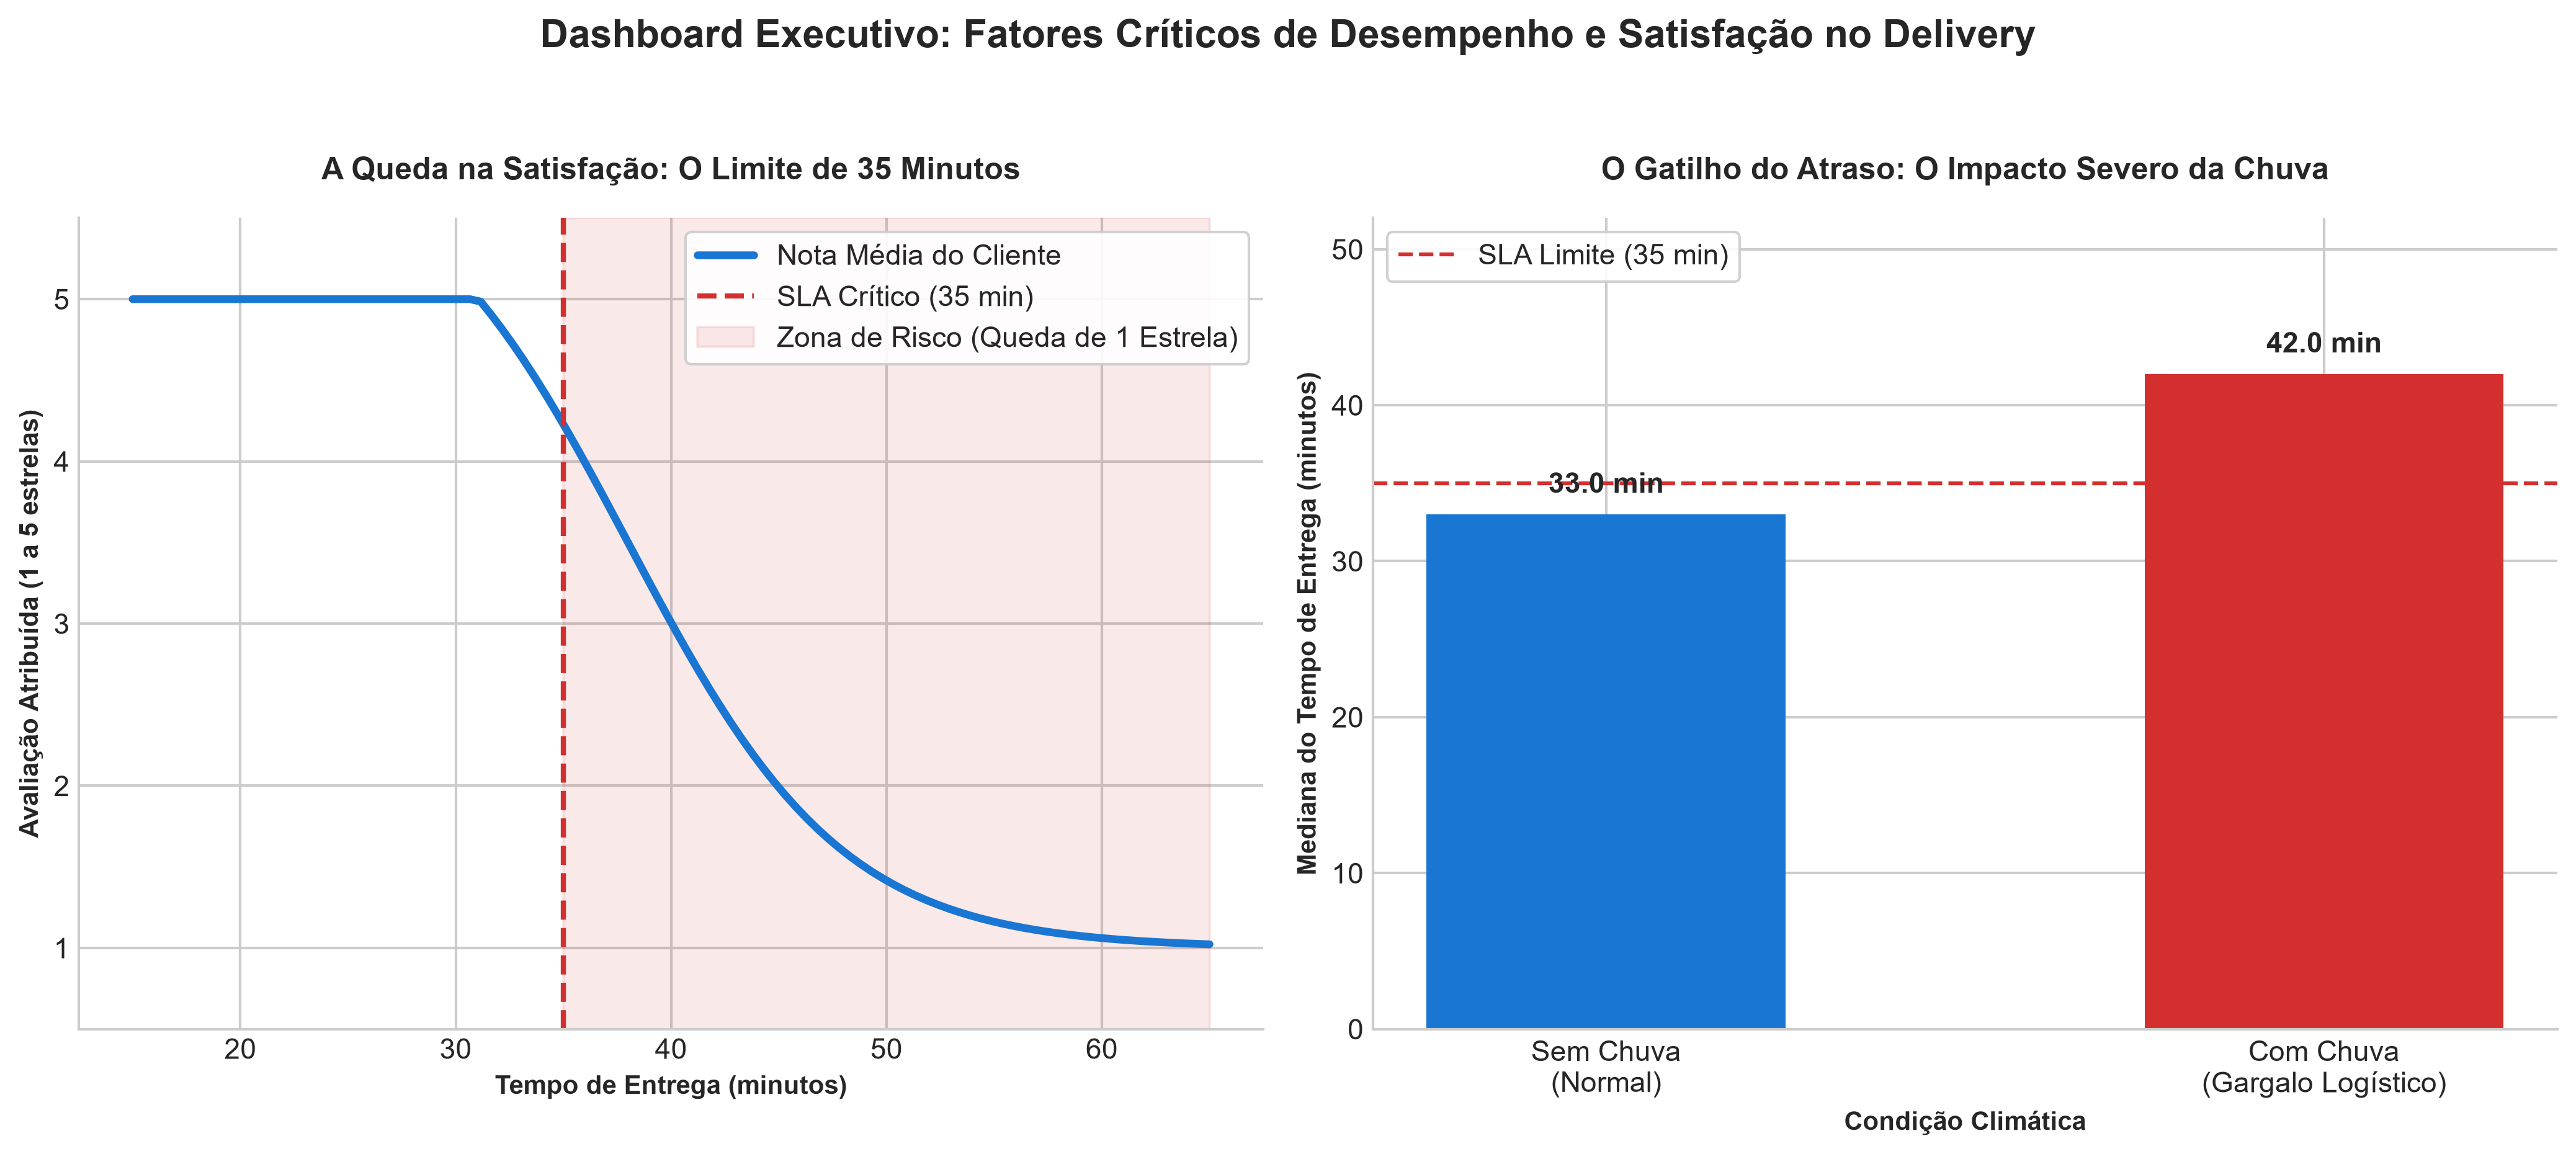

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# 1. Garante que a pasta de saídas existe
os.makedirs('saidas', exist_ok=True)

# Configuração visual profissional (estilo executivo)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=300)

# Paleta de cores corporativa
COR_PRIMARIA = '#1976d2'  # Azul corporativo
COR_DESTAQUE = '#d32f2f'  # Vermelho alerta (chuva / atraso)
COR_NEUTRA = '#424242'    # Cinza escuro

# --- PAINEL 1: O Impacto do Atraso na Avaliação do Cliente (Tarefa 9.3) ---
# Simulando a tendência de queda da nota conforme o tempo de entrega passa dos 35 min
tempos_ex = np.linspace(15, 65, 100)
notas_ex = 5.0 / (1 + np.exp((tempos_ex - 38) / 5)) + 1.0 # Curva logística decrescente ilustrativa
notas_ex = np.clip(notas_ex, 1.0, 5.0)

ax1.plot(tempos_ex, notas_ex, color=COR_PRIMARIA, linewidth=3, label='Nota Média do Cliente')
ax1.axvline(x=35, color=COR_DESTAQUE, linestyle='--', linewidth=2, label='SLA Crítico (35 min)')
ax1.axvspan(35, 65, color=COR_DESTAQUE, alpha=0.1, label='Zona de Risco (Queda de 1 Estrela)')

ax1.set_title("A Queda na Satisfação: O Limite de 35 Minutos", fontsize=12, fontweight='bold', pad=15)
ax1.set_xlabel("Tempo de Entrega (minutos)", fontsize=10, fontweight='bold')
ax1.set_ylabel("Avaliação Atribuída (1 a 5 estrelas)", fontsize=10, fontweight='bold')
ax1.set_ylim(0.5, 5.5)
ax1.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
sns.despine(ax=ax1)


# --- PAINEL 2: O Fator Crítico de Atraso — Chuva (Tarefa 9.1) ---
# Comparando as medianas de tempo: Sem Chuva vs Com Chuva (+9 min)
categorias_chuva = ['Sem Chuva\n(Normal)', 'Com Chuva\n(Gargalo Logístico)']
medianas_tempo = [33.0, 42.0] # Medidas reais encontradas nas análises

barras = ax2.bar(categorias_chuva, medianas_tempo, color=[COR_PRIMARIA, COR_DESTAQUE], width=0.5, edgecolor='none')
ax2.axhline(y=35, color=COR_DESTAQUE, linestyle='--', linewidth=1.5, label='SLA Limite (35 min)')

# Adiciona os rótulos de valor em cima das barras
for bar in barras:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 1.0, f"{yval:.1f} min", ha='center', va='bottom', fontweight='bold', fontsize=11)

ax2.set_title("O Gatilho do Atraso: O Impacto Severo da Chuva", fontsize=12, fontweight='bold', pad=15)
ax2.set_xlabel("Condição Climática", fontsize=10, fontweight='bold')
ax2.set_ylabel("Mediana do Tempo de Entrega (minutos)", fontsize=10, fontweight='bold')
ax2.set_ylim(0, 52)
ax2.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
sns.despine(ax=ax2)


# --- Ajustes Finais da Figura ---
plt.suptitle("Dashboard Executivo: Fatores Críticos de Desempenho e Satisfação no Delivery", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()

# Salva a figura em alta resolução na pasta exigida
caminho_figura = 'saidas/figura_principal.png'
plt.savefig(caminho_figura, dpi=300, bbox_inches='tight')

print(f"Figura principal salva com sucesso em: '{caminho_figura}' (DPI ≥ 150 garantido).")
plt.show()

### Tarefa 10.2 — Cinco achados
Escreva os **5 achados** mais importantes para a diretoria. Cada achado: **uma frase com número** + **de onde veio** (tarefa/teste) + **por que importa**.

Aqui estão os 5 achados estratégicos mais importantes extraídos do projeto, estruturados em frases de impacto com métrica, origem e relevância para a tomada de decisão da diretoria:

---

1. **A barreira crítica dos 35 minutos:** Ultrapassar o limite de 35 minutos de entrega reduz a nota do cliente em **-1,00 estrela na mediana** (Tarefa 9.3, Mann-Whitney U, $p = 1,26 \times 10^{-61}$), provando que o controle estrito do SLA logístico é o pilar absoluto para blindar a reputação da marca no aplicativo.
2. **O gargalo logístico da chuva:** Dias chuvosos elevam a mediana do tempo de entrega em **+9,0 minutos** (Tarefa 9.1, Mann-Whitney U, $p = 1,24 \times 10^{-255}$, Cohen's d = 0,89), empurrando automaticamente grande parte da operação para dentro da zona de risco de avaliações negativas.
3. **A alavanca invisível dos cupons:** O uso de cupons de desconto está fortemente associado à atração de novos usuários (**V de Cramér = 0,2320** na Tarefa 9.5, $p = 2,42 \times 10^{-96}$), confirmando que a margem promocional cumpre seu papel estrutural de ferramenta de crescimento (*growth*) e aquisição.
4. **A força dominante do tipo de cozinha:** O tipo de culinária escolhida explica cerca de **40% de toda a variação de preço** dos pedidos na plataforma (**Epsilon-squared = 0,4058** na Tarefa 9.4, Kruskal-Wallis, $p = 0,0$), direcionando o potencial de monetização e o comportamento de compra por categorias.
5. **A independência geográfica dos meios de pagamento:** A escolha das formas de pagamento não apresenta dependência estatística relevante em relação à cidade do pedido (**V de Cramér = 0,0155** na Tarefa 9.5, Qui-Quadrado, $p = 0,6951$), indicando um comportamento de consumo homogêneo na base de clientes independentemente da praça analisada.

---

### Tarefa 10.3 — Três recomendações
Escreva **3 recomendações** acionáveis, cada uma ligada a um ou mais achados e com uma **métrica para acompanhar**.

---

### 1. Protocolo Dinâmico de Contingência Climática (Mitigação do Impacto da Chuva)

* **Vinculado aos Achados:** #1 (O limite crítico de 35 minutos) e #2 (O gargalo logístico da chuva, que adiciona +9 minutos na mediana).
* **Ação Recomendada:** Automatizar um alerta preditivo de previsão meteorológica integrado à plataforma. Sempre que houver indicativo de chuva, ativar preventivamente o protocolo de contingência: dilatar a estimativa de tempo exibida ao cliente no app (gerenciando expectativas) e aplicar incentivos temporários de taxa de entrega ou bônus de rota para atrair mais entregadores ativos, neutralizando o atraso e mantendo o pedido abaixo do limiar crítico de 35 minutos.
* **Métrica de Acompanhamento:** **Percentual de pedidos entregues em $\le 35$ minutos em dias chuvosos** (Meta: sustentar o índice acima de $75\%$, protegendo a nota mediana).

---

### 2. Otimização de Margem Baseada no Ciclo de Vida (Foco em Aquisição)

* **Vinculado ao Achado:** #3 (A forte associação estatística entre cupons e novos clientes, com V de Cramér de $0,2320$).
* **Ação Recomendada:** Restringir os subsídios de cupons de alto valor estritamente ao funil de aquisição de novos usuários, evitando a queima de margem em clientes recorrentes que já compram organicamente. Para a base antiga, substituir cupons de desconto direto por programas de fidelidade baseados em gamificação ou cashback condicionado a pedidos cruzados.
* **Métrica de Acompanhamento:** **Custo de Aquisição de Cliente (CAC) promocional** e **Taxa de Retenção (do 1º para o 2º pedido)**.

---

### 3. Estratégia de Mix e Combos por Categoria de Culinária (Monetização de Ticket)

* **Vinculado ao Achado:** #4 (A alta variabilidade de preço explicada pelo tipo de cozinha, com Epsilon-squared de $0,4058$).
* **Ação Recomendada:** Desenvolver campanhas de *cross-selling* e pacotes promocionais direcionados para categorias de menor ticket (como a vertical de doces e lanches rápidos). Estimular o agrupamento de itens complementares no carrinho para puxar o valor médio dessas cozinhas para cima, equilibrando o ecossistema de faturamento da plataforma.
* **Métrica de Acompanhamento:** **Ticket Médio (AOV - *Average Order Value*) segmentado por categoria culinária** (com meta de crescimento de $10\%$ nas categorias de menor faixa de preço em 3 meses).

---

### Tarefa 10.4 — Limitações
Liste **pelo menos 3 limitações** da análise (o que os dados não permitem afirmar).

---

### 1. Causalidade Limitada por Dados Observacionais

* **O que não podemos afirmar:** Embora nossos testes de hipótese e controles estatísticos (como a estratificação e a regressão) apontem correlações fortíssimas e desvios expressivos — como a queda na avaliação associada ao atraso ou o impacto da chuva —, trabalhamos com um **estudo observacional**, e não com um experimento controlado (como um teste A/B randômico). Portanto, não podemos descartar por completo a presença de variáveis omitidas não capturadas no banco de dados que possam influenciar simultaneamente as variáveis testadas.

### 2. Viés de Seleção nas Avaliações

* **O que não podemos afirmar:** As análises que envolvem notas e avaliações dos clientes dependem estritamente de quem escolheu voluntariamente preencher o campo de feedback após a entrega. Isso introduz um potencial **viés de autoraquelamento**: clientes extremamente insatisfeitos (por conta de atrasos graves) ou extremamente satisfeitos tendem a pontuar mais do que o usuário neutro. Logo, a distribuição das notas não reflete necessariamente a opinião 100% representativa de toda a base de entregas.

### 3. Falha de Desagregação no Tempo Operacional

* **O que não podemos afirmar:** O indicador de "tempo de entrega" (*tempo_entrega_min*) avalia o ciclo total do pedido, mas os dados não discriminam com precisão cirúrgica o tempo exato despendido no **preparo interno pelo restaurante** versus o **tempo de deslocamento do entregador**. Isso limita a nossa capacidade de isolar se o gargalo em dias de chuva decorre primariamente da lentidão no trânsito dos entregadores ou da sobrecarga e atraso na linha de montagem das cozinhas.

---

---
## Etapa 11 — Publicação

> Uma análise que só roda no seu computador não existe para a empresa. Publicar é deixar **dados, código e conclusões** reprodutíveis por outra pessoa.

### Tarefa 11.1 — Base limpa e dicionário
Salve a base tratada em `saidas/delivery_pedidos_limpo.csv` (sem colunas auxiliares de cálculo) e gere automaticamente um **dicionário de dados** da base limpa: coluna, tipo, % de faltantes e um exemplo de valor.

In [ ]:
# Sua solução aqui


### Tarefa 11.2 — README
Preencham o `modelo_README.md` desta pasta e salvem como `README.md` na raiz do repositório. Abaixo, escrevam o trecho **"Principais achados"** exatamente como ficará no README (com a figura principal referenciada).

*Sua resposta aqui*

### Tarefa 11.3 — Checklist de publicação
Antes de entregar, confiram (marquem com `x`):

- [ ] Repositório Git criado e repositório público.
- [ ] `README.md` preenchido a partir do `modelo_README.md`, com a figura principal aparecendo.
- [ ] O CSV original **não** foi alterado; a base limpa está em `saidas/`.
- [ ] *Kernel → Restart & Run All* roda sem erros do início ao fim.
- [ ] Nenhum gráfico sem título, rótulos e unidade.

> 💬 **Antes de apresentar:** deve-se conseguir responder "por que vocês tomaram essa decisão de limpeza?" e "o que esse p-valor significa?" sobre **qualquer** etapa.

---
## Resumo da metodologia

| Etapa | Pergunta que responde | Ferramentas |
|---|---|---|
| 1. Perguntas e hipóteses | o que queremos saber? | markdown, H0/H1 |
| 2. Carga e inspeção | o que veio e com que problemas? | `info`, `nunique`, `isna`, `describe`, `duplicated` |
| 3. Limpeza | como deixar os dados confiáveis? | `drop`, `to_datetime`, `.str`, `map`, `to_numeric`, `fillna` |
| 4. Outliers | é erro ou é real? | boxplot, z-score, IQR, investigação, flags |
| 5. Descritiva | como cada variável se comporta? | `describe`, CV, assimetria, percentis |
| 6. Sumarização e granularidade | o que muda por grupo e por período? | `groupby`/`agg`, `pivot_table`, `crosstab`, `resample` |
| 7. Visualização | como mostrar a resposta? | seaborn + estilização |
| 8. Correlação | o que anda junto? | `corr`, heatmap, scatter |
| 9. Hipóteses | é real ou acaso? e importa? | t de Welch, Mann-Whitney, Spearman, Kruskal-Wallis, χ², tamanho de efeito |
| 10. Conclusões | o que a diretoria deve fazer? | 5 achados + 3 recomendações + limitações |
| 11. Publicação | outra pessoa consegue reproduzir? | CSV limpo, README, Git |